# Sarampo no estado de São Paulo em 2019
## Caracterização epidemiológica e modelagem preditiva municipal — PTC3567

**Pergunta central:** quando, onde e em quais grupos se concentraram os casos de sarampo de 2019 no estado de São Paulo? Como a qualidade dos registros e a cobertura vacinal municipal anterior à epidemia condicionam a interpretação?

Notebook em português brasileiro, preparado em 11/11/2026. Utiliza os arquivos nacionais **EXANBR19 e EXANBR20 fornecidos pelo usuário**, além de população, malha municipal, cobertura vacinal e PIB por habitante. Os resultados são descritivos e exploratórios, sem inferência causal.

**Organização do projeto:** este notebook fica na raiz e lê os arquivos de `data/processed`. As fontes recebidas estão em `data/raw`; `scripts/prepare_data.py` reconstrói todos os dados processados a partir delas. Consulte `README.md` para executar e `FONTES.md` para origem, filtros e limitações. Os resultados já estão executados. Não é necessário acessar a internet para reconstruir os dados após instalar as dependências.

**Unidade principal:** uma notificação classificada como sarampo, de residente de São Paulo, com início do exantema em 2019. Sem identificador individual público, não se deve interpretar automaticamente cada linha como uma pessoa única.

**Extensão de machine learning:** a seção 12 compara modelos municipais em validação geográfica aninhada. O objetivo é avaliar a capacidade de generalização e a contribuição incremental da vacinação, inclusive quando os resultados são negativos. O estudo é retrospectivo e não estima efeitos causais.

In [1]:
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from scipy.stats import chi2, spearmanr
from IPython.display import display
plt.rcParams.update({'figure.figsize':(11,5), 'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.titleweight':'bold', 'axes.titlepad':14})
AZUL='#167d9a'; LARANJA='#d67535'; CINZA='#a6adb4'
MESES=['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
def ic_poisson(k,p):
    k=np.asarray(k,float);p=np.asarray(p,float)
    return np.where(k>0,chi2.ppf(.025,2*k)/2,0)/p*1e5, chi2.ppf(.975,2*(k+1))/2/p*1e5
def wilson(k,n):
    k=np.asarray(k,float);n=np.asarray(n,float);p=np.divide(k,n,out=np.full_like(k,np.nan),where=n>0)
    den=1+1.96**2/n; mid=(p+1.96**2/(2*n))/den
    half=1.96*np.sqrt(p*(1-p)/n+1.96**2/(4*n*n))/den
    return (mid-half)*100,(mid+half)*100

In [2]:
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'data' / 'processed' / 'notificacoes.csv').exists():
    raise FileNotFoundError('Abra o notebook na raiz do projeto e execute: python scripts/prepare_data.py')
PROCESSED = ROOT / 'data' / 'processed'
RAW = ROOT / 'data' / 'raw'
def ler_csv(nome, **kwargs):
    return pd.read_csv(PROCESSED / nome, **kwargs)
# Verifica os hashes das fontes e dos arquivos derivados antes da análise.
manifesto = json.loads((PROCESSED / 'manifesto_processamento.json').read_text(encoding='utf-8'))
for registro in manifesto['arquivos']:
    caminho = ROOT / registro['arquivo']
    assert hashlib.sha256(caminho.read_bytes()).hexdigest() == registro['sha256'], f'Arquivo alterado: {caminho}'
notificacoes=ler_csv('notificacoes.csv',dtype=str,keep_default_na=False)
municipios=ler_csv('municipios.csv',dtype={'codigo':str}).set_index('codigo')
pop_idade=ler_csv('pop_idade.csv',dtype={'codigo':str}).set_index('codigo')
pop_sexo=ler_csv('pop_sexo.csv',dtype={'codigo':str}).set_index('codigo')
vacinas=ler_csv('mmr.csv',dtype={'municipality_ibge':str})
pib=ler_csv('pib.csv',dtype={'municipality_ibge':str})
malha=json.loads((PROCESSED / 'malha.json').read_text(encoding='utf-8'))
fontes=json.loads((PROCESSED / 'fontes.json').read_text(encoding='utf-8'))
print(f'{len(notificacoes):,} notificações nacionais; {len(municipios)} municípios; {len(vacinas):,} registros de cobertura vacinal.')

86,702 notificações nacionais; 645 municípios; 3,870 registros de cobertura vacinal.


### Principais resultados

- **18.025 casos**, **307 municípios**, incidência estadual de **39,78 por 100 mil**.
- Pico semanal entre **11 e 17 de agosto**; julho–setembro concentram **72,4%** dos exantemas registrados.
- **20–29 anos:** maior número de casos; **menores de 1 ano:** maior incidência.
- **2.249 hospitalizações** e **18 óbitos pelo agravo**, com informação ausente que limita a interpretação.
- D2 de 2018 e incidência municipal: associação negativa fraca (**ρ≈−0,18**), reduzida para **−0,10** ao excluir coberturas >100%. Densidade apresenta associação positiva mais forte (**ρ≈0,55**), sem demonstrar causalidade.

As seções seguintes mostram como esses resultados foram calculados, quais escolhas os alteram e o que não se pode concluir.

## 1. Fontes, transformação e definições

| Base | Recorte | Uso e ressalva |
|---|---|---|
| SINAN, EXANBR19.dbc e EXANBR20.dbc | Notificações de 2019 e 2020, Brasil | Seleção por residência, classificação final e data do exantema; inclui notificações tardias de 2020 |
| População municipal por idade e sexo, Ministério da Saúde | 2019, tabela `popsvs2024br.def` | Denominador principal; série revisada, diferente da estimativa originalmente publicada |
| IBGE, estimativa municipal | 2019, arquivo revisado em 2022 | Sensibilidade do denominador |
| SI-PNI, cobertura administrativa | 645 municípios, 2016–2018, D1 e D2 | Extração histórica recebida; proveniência informa espelho público, não nova consulta direta ao SI-PNI |
| IBGE, PIB municipal | 2016 | Contexto econômico; não equivale à renda familiar nem à desigualdade |
| IBGE, malha municipal | 2019 | Mapas e área territorial |

Conversão realizada: `dbc-to-dbf 1.0.1` descompactou os dois DBC; `dbfread 2.0.7` leu os DBF com codificação Latin-1. Foram preservados 31 campos necessários, sem nomes, endereços ou texto livre. Datas convertidas para ISO, demais códigos mantidos como texto. Os hashes abaixo identificam os arquivos recebidos, mas não certificam sua origem. O Parquet anterior de 2019 não foi somado ao DBC: representam a mesma base.

**Códigos essenciais:** `CLASSI_FIN=1` identifica sarampo; `SG_UF=35`, residência paulista. `DT_INICIO_` é início do exantema, distinto de `DT_SIN_PRI` e `DT_NOTIFIC`. `CS_VACINA` é antecedente vacinal; **`CS_VACINAL` descreve bloqueio vacinal**, não o estado vacinal do paciente. `ID_HOSPIT`: 1 sim, 2 não, 9 ignorado. Evolução: 1 cura, 2 óbito pelo agravo, 3 outra causa, 9 ignorado.

Fontes documentais: [dicionário de exantemáticas do Ministério da Saúde](https://goias.gov.br/saude/wp-content/uploads/sites/34/2013/08/exantematica1-b5a.pdf), [TabNet de casos](https://tabnet.datasus.gov.br/cgi/deftohtm.exe?sinannet/cnv/exantbr.def), [população por idade e sexo](https://tabnet.datasus.gov.br/cgi/deftohtm.exe?ibge/cnv/popsvs2024br.def), [estimativas IBGE](https://ftp.ibge.gov.br/Estimativas_de_Populacao/Estimativas_2019/), [malha IBGE](https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/UFs/SP/), [espelho SI-PNI declarado na proveniência](https://huggingface.co/datasets/SidneyBissoli/sipni-agregados-cobertura).

As consultas TabNet, seus parâmetros e hashes, e a proveniência vacinal estão em `data/raw`. O manifesto em `data/processed/manifesto_processamento.json` verifica os arquivos usados; `FONTES.md` descreve sua origem.

In [3]:
display(pd.DataFrame(fontes))
for c in ['DT_NOTIFIC','DT_SIN_PRI','DT_INICIO_','DT_INVEST','DT_ENCERRA','DT_INTERNA','DT_OBITO','DT_DOSE_N']:
    notificacoes[c+'_data']=pd.to_datetime(notificacoes[c],errors='coerce')
sp=notificacoes[notificacoes.SG_UF.eq('35')].copy()
confirmados=sp[sp.CLASSI_FIN.eq('1')].copy()
coorte=confirmados[confirmados.DT_INICIO__data.dt.year.eq(2019)].copy()
N=len(coorte); POP=municipios.populacao.sum()
fluxo=pd.Series({'Notificações nacionais, dois arquivos':len(notificacoes),
                 'Residentes de São Paulo':len(sp), 'Classificação final sarampo':len(confirmados),
                 'Exantema em 2019 — coorte principal':N,
                 'Exantema em outro ano':int((confirmados.DT_INICIO__data.notna() & ~confirmados.DT_INICIO__data.dt.year.eq(2019)).sum()),
                 'Exantema sem data válida':int(confirmados.DT_INICIO__data.isna().sum())},name='Registros')
display(fluxo.to_frame())
display(pd.crosstab(coorte.arquivo,coorte.DT_NOTIFIC_data.dt.year, margins=True))
assert N==18025 and coorte.ID_MN_RESI.isin(municipios.index).all()

,arquivo,sha256,linhas,colunas
0,data/raw/EXANBR19.dbc,4a57515ba25ddef87f587ac9bd82a7985c0e1d806e1fe3b87b814abf74daa47d,68765,107.00
1,data/raw/EXANBR20.dbc,7539124381d2ee9e5609f91025c753bf63b2b04d5dbbda2dbbfebb1455eb6552,17937,107.00
2,data/raw/mmr_2016_2018.csv,794ee20ee4c6f4e082131e535b477b35739d1da55fc8f02d5f3449b9ae89f4a8,3870,NaN
3,data/raw/gdp_per_capita_2016.csv,4bfe59b6896af4d0faf6fbe93d1b5bd1fc4987d73b6d04c75ff022632b6f82d7,645,NaN


,Registros
"Notificações nacionais, dois arquivos",86702
Residentes de São Paulo,57404
Classificação final sarampo,18977
Exantema em 2019 — coorte principal,18025
Exantema em outro ano,885
Exantema sem data válida,67


DT_NOTIFIC_data,2019,2020,All
arquivo,,,
EXANBR19.dbc,17970,0,17970
EXANBR20.dbc,0,55,55
All,17970,55,18025


### Coerência do recorte

A seleção recupera **18.025 registros**: 17.970 no arquivo de 2019 e **55 no de 2020**. O resultado concorda com o total TabNet obtido anteriormente para residência paulista e exantema em 2019. A coorte de notificações feitas em 2019, independentemente da data do exantema, é outro universo e não deve ser usada como sinônimo.

Os arquivos não representam somente São Paulo: contêm notificações nacionais. O foco estadual é uma decisão analítica, não evidência de que a epidemia tenha sido exclusiva do estado. A inclusão de EXANBR20 corrige parte do truncamento do ano de notificação; eventuais notificações posteriores a 2020 não estão nos microdados recebidos.

## 2. Qualidade, incompletude e consistência

Branco e código ignorado são tratados como informação desconhecida, nunca como “não”. A ausência de uma data de internação para quem não foi internado é estrutural, e não um erro. A análise distingue completude, validade do código e coerência entre datas. Registros semelhantes não são excluídos sem identificador individual.

,conhecidos,desconhecidos,desconhecidos_%
campo,,,
CS_SEXO,18022,3,0.02
CS_VACINA,14781,3244,18.00
ID_HOSPIT,16306,1719,9.54
EVOLUCAO,15271,2754,15.28
CRITERIO,17963,62,0.34
ID_TOSSE,17612,413,2.29
ID_CORIZA,17525,500,2.77
ID_CONJUNT,17299,726,4.03
TPAUTOCTO,14765,3260,18.09


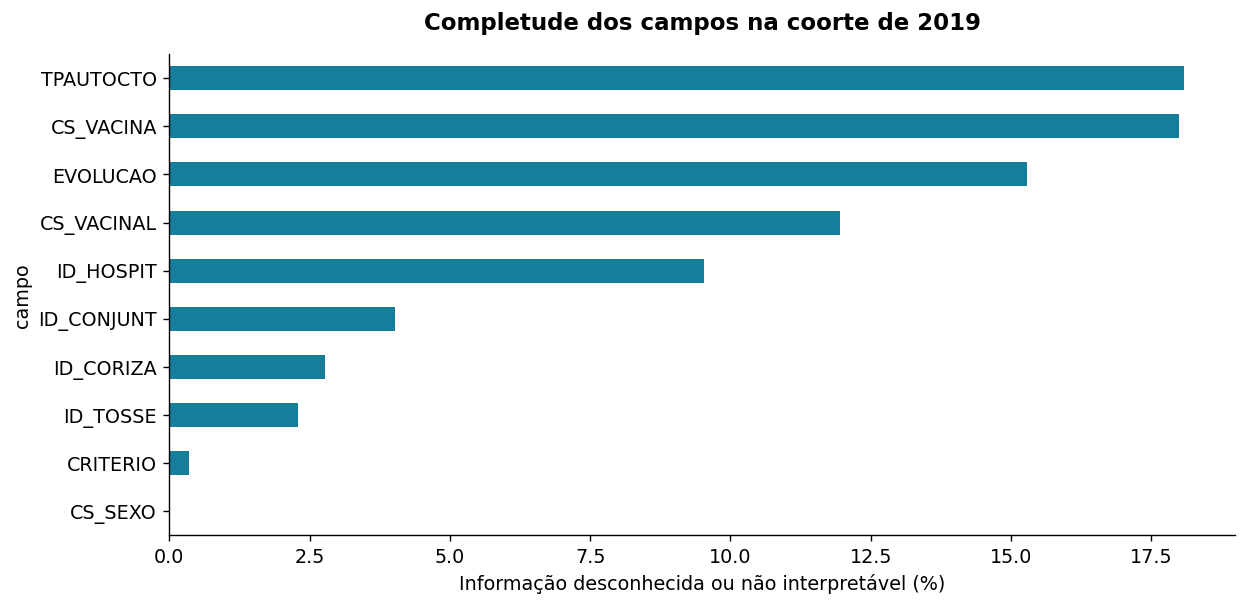

,Registros
Linhas iguais nos campos disponibilizados (sem arquivo),2
Notificação anterior ao exantema,0
Investigação anterior à notificação,0
Encerramento anterior à notificação,0
Internação=sim sem data válida,88
Vacina=sim sem data da última dose,1476


In [4]:
validos={'CS_SEXO':['M','F'],'CS_VACINA':['1','2'],'ID_HOSPIT':['1','2'],
         'EVOLUCAO':['1','2','3'],'CRITERIO':['1','2','3','4'],
         'ID_TOSSE':['1','2'],'ID_CORIZA':['1','2'],'ID_CONJUNT':['1','2'],
         'TPAUTOCTO':['1','2'],'CS_VACINAL':['1','2','3','4']}
qualidade=pd.DataFrame([{'campo':c,'conhecidos':coorte[c].isin(v).sum(),
                         'desconhecidos':(~coorte[c].isin(v)).sum()} for c,v in validos.items()]).set_index('campo')
qualidade['desconhecidos_%']=100*qualidade.desconhecidos/N
display(qualidade)
qualidade['desconhecidos_%'].sort_values().plot.barh(color=AZUL)
plt.xlabel('Informação desconhecida ou não interpretável (%)');plt.title('Completude dos campos na coorte de 2019');plt.show()
coorte['atraso']=(coorte.DT_NOTIFIC_data-coorte.DT_INICIO__data).dt.days
coorte['investigacao_dias']=(coorte.DT_INVEST_data-coorte.DT_NOTIFIC_data).dt.days
coorte['encerramento_dias']=(coorte.DT_ENCERRA_data-coorte.DT_NOTIFIC_data).dt.days
controle=pd.Series({'Linhas iguais nos campos disponibilizados (sem arquivo)':int(coorte[[c for c in notificacoes.columns if c!='arquivo']].duplicated().sum()),
 'Notificação anterior ao exantema':int((coorte.atraso<0).sum()),
 'Investigação anterior à notificação':int((coorte.investigacao_dias<0).sum()),
 'Encerramento anterior à notificação':int((coorte.encerramento_dias<0).sum()),
 'Internação=sim sem data válida':int((coorte.ID_HOSPIT.eq('1') & coorte.DT_INTERNA_data.isna()).sum()),
 'Vacina=sim sem data da última dose':int((coorte.CS_VACINA.eq('1') & coorte.DT_DOSE_N_data.isna()).sum())},name='Registros')
display(controle.to_frame())

**O problema anterior das datas foi localizado na tabulação, não na ausência generalizada dos microdados.** A extração agregada tinha 76,7% no mês de exantema ignorado e apenas outubro–dezembro discriminados. Aqui, o campo original permite recuperar os meses de todo o ano. A causa técnica exata da anomalia do TabNet não foi demonstrada; não é correto imputar aqueles casos aos meses finais.

A completude de exantema é 100% **na coorte selecionada**, pois o filtro exige uma data de 2019. Isso não comprova completude perfeita na base original: o fluxograma apresenta os registros excluídos por ausência de data. Duas linhas são idênticas no subconjunto de campos processado, mas não são duplicatas exatas nos 107 campos originais (verificação antes da seleção: zero duplicata exata na coorte). Portanto, foram mantidas. Sem identificador, igualdade de características não demonstra duplicação da pessoa.

Datas negativas nos intervalos são sinalizadas, sem reescrever o registro; uma notificação pode anteceder o exantema clinicamente, embora o dicionário imponha uma ordem esperada.

## 3. Dimensão da epidemia e distribuição territorial

Incidência acumulada = casos com exantema em 2019 / população residente em 2019 × 100.000. Não é uma taxa por pessoa-tempo. Municípios sem registros são mantidos na análise; zero registrado não comprova ausência de transmissão. Intervalos de Poisson de 95% ilustram a instabilidade das contagens, mas não cobrem subnotificação ou erros de população.

,Valor
Casos,"18,025.00"
População,"45,306,139.00"
Incidência por 100 mil,39.78
Municípios com casos,307.00
Municípios sem casos,338.00
Casos na capital (%),52.11
Casos nos 10 municípios com mais registros (%),74.03


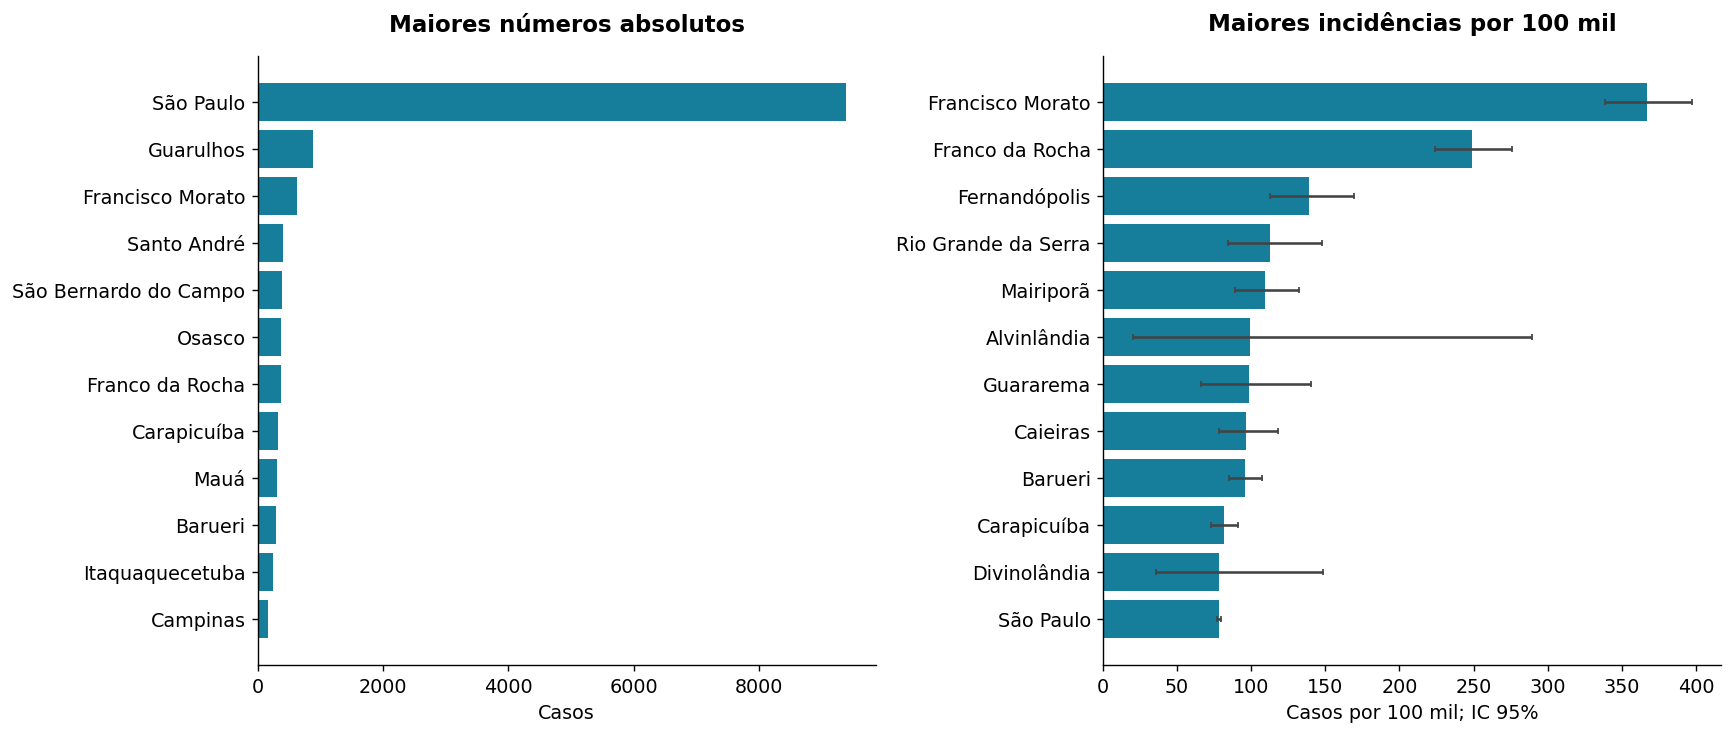

,municipio,casos,populacao,incidencia,ic_inf,ic_sup
codigo,,,,,,
351630,Francisco Morato,621,169229,366.96,338.66,396.99
351640,Franco da Rocha,365,146664,248.87,223.99,275.76
351550,Fernandópolis,99,71271,138.91,112.90,169.11
354410,Rio Grande da Serra,52,46087,112.83,84.27,147.96
352850,Mairiporã,101,92698,108.96,88.75,132.39
350150,Alvinlândia,3,3027,99.11,20.44,289.64
351830,Guararema,30,30531,98.26,66.30,140.27
350900,Caieiras,93,96305,96.57,77.94,118.30
350570,Barueri,290,302517,95.86,85.15,107.55


In [5]:
municipios['casos']=coorte.ID_MN_RESI.value_counts().reindex(municipios.index,fill_value=0)
municipios['incidencia']=municipios.casos/municipios.populacao*1e5
municipios['densidade']=municipios.populacao/municipios.area_km2
municipios['ic_inf'],municipios['ic_sup']=ic_poisson(municipios.casos,municipios.populacao)
resumo=pd.Series({'Casos':N,'População':POP,'Incidência por 100 mil':N/POP*1e5,
 'Municípios com casos':(municipios.casos>0).sum(),'Municípios sem casos':(municipios.casos==0).sum(),
 'Casos na capital (%)':100*municipios.loc['355030','casos']/N,
 'Casos nos 10 municípios com mais registros (%)':100*municipios.casos.nlargest(10).sum()/N})
display(resumo.to_frame('Valor'))
fig,axs=plt.subplots(1,2,figsize=(14,6))
for ax,col,title in zip(axs,['casos','incidencia'],['Maiores números absolutos','Maiores incidências por 100 mil']):
    top=municipios.nlargest(12,col).sort_values(col)
    ax.barh(top.municipio,top[col],color=AZUL)
    if col=='incidencia': ax.errorbar(top[col],top.municipio,xerr=[top[col]-top.ic_inf,top.ic_sup-top[col]],fmt='none',ecolor='#444',capsize=2)
    ax.set_title(title);ax.set_xlabel('Casos' if col=='casos' else 'Casos por 100 mil; IC 95%')
plt.tight_layout();plt.show()
display(municipios.nlargest(15,'incidencia')[['municipio','casos','populacao','incidencia','ic_inf','ic_sup']])

A capital reúne **52.1%** dos registros. Entretanto, a maior incidência municipal é observada em **Francisco Morato**, com **367.0 casos por 100 mil**. Número absoluto orienta a carga de atendimento; incidência ajuda a comparar populações de tamanhos diferentes. O ranking não é uma classificação definitiva de risco: municípios pequenos têm estimativas mais instáveis e a captação de casos varia.

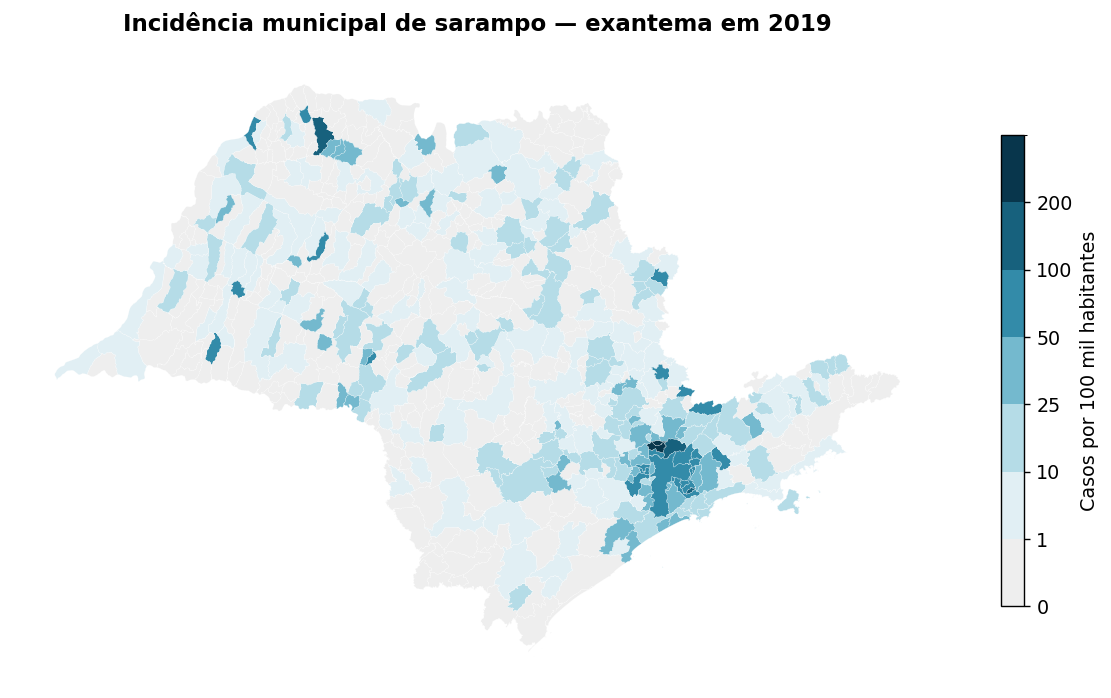

In [6]:
limites=[0,1,10,25,50,100,200,1000]
cmap=ListedColormap(['#eeeeee','#e1eff4','#b5dce7','#74b9ce','#338ba9','#17617d','#08364c'])
norm=BoundaryNorm(limites,cmap.N)
fig,ax=plt.subplots(figsize=(12,7));vertices=[];valores=[]
for cod,partes in malha.items():
    for parte in partes:
        vertices.append(np.asarray(parte));valores.append(municipios.loc[cod,'incidencia'])
pc=PolyCollection(vertices,array=np.array(valores),cmap=cmap,norm=norm,edgecolors='white',linewidths=.12)
ax.add_collection(pc);ax.autoscale_view();ax.set_aspect(1/np.cos(np.deg2rad(23)));ax.set_axis_off()
ax.set_title('Incidência municipal de sarampo — exantema em 2019')
fig.colorbar(pc,ax=ax,shrink=.7,label='Casos por 100 mil habitantes',ticks=limites[:-1]);plt.show()

O mapa usa **município de residência**, não o local provável de infecção. Não permite reconstruir trajetórias de transmissão ou concluir que os casos foram adquiridos no município. A maior área visual dos municípios extensos não representa maior população.

## 4. Curva epidêmica, notificações tardias e expansão municipal

A curva principal usa **data de início do exantema**. Para evitar confusão com a semana epidemiológica oficial do SINAN, os agrupamentos semanais abaixo são explicitamente intervalos de **domingo a sábado**; o eixo indica o domingo inicial. A curva de notificação é mostrada como comparação do processo de vigilância.

Semana com mais exantemas: 2019-08-11 a 2019-08-17 ; casos: 1351
Parcela de julho a setembro: 72.44 %


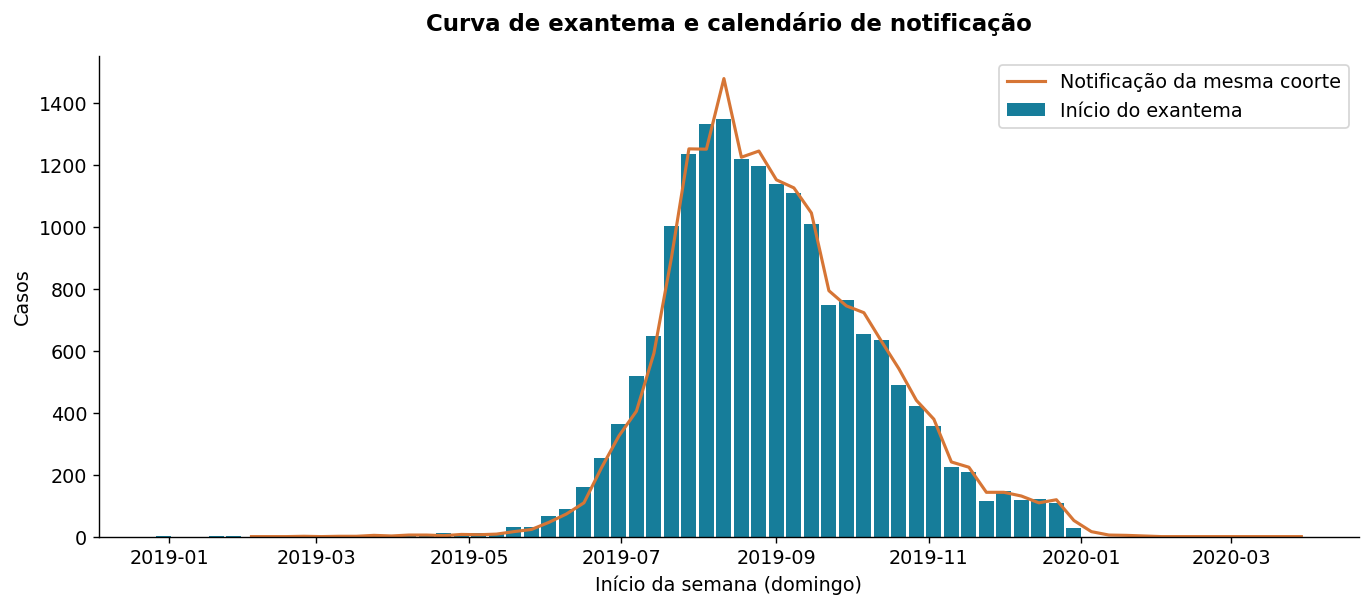

,mes,casos,percentual
0,Jan,6,0.03
1,Fev,11,0.06
2,Mar,18,0.10
3,Abr,34,0.19
4,Mai,87,0.48
5,Jun,618,3.43
6,Jul,3222,17.88
7,Ago,5616,31.16
8,Set,4219,23.41
9,Out,2662,14.77


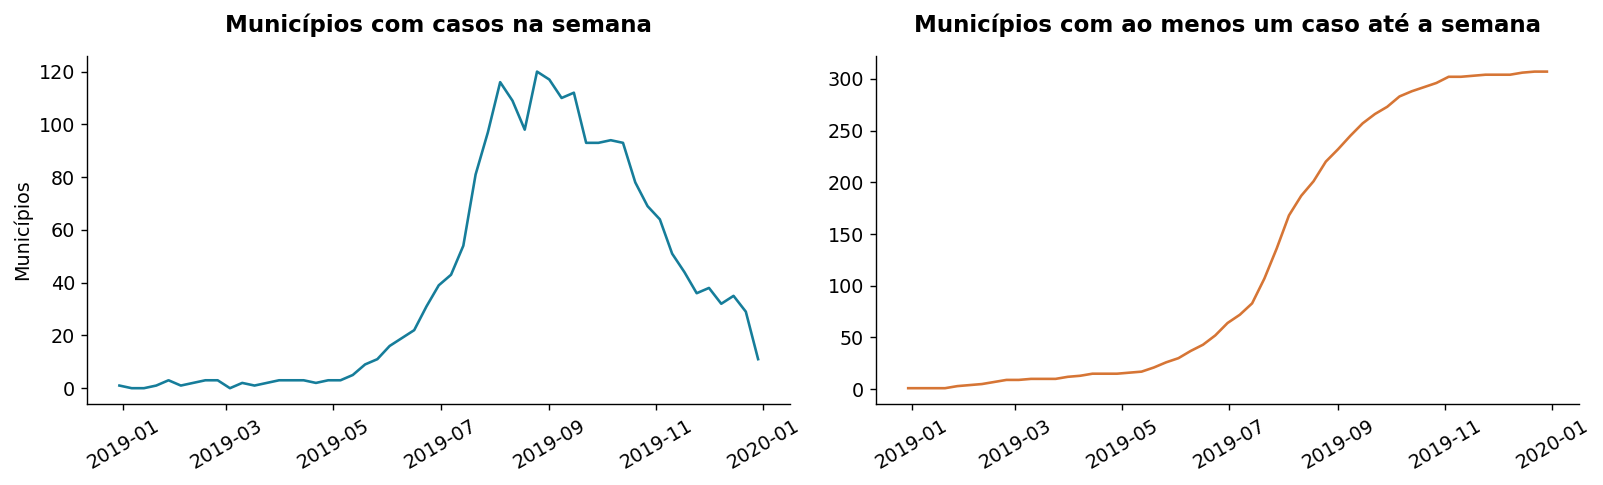

In [7]:
coorte['semana_inicio']=coorte.DT_INICIO__data.dt.to_period('W-SAT').dt.start_time
semanas=pd.date_range('2018-12-30','2019-12-29',freq='7D')
curva=coorte.groupby('semana_inicio').size().reindex(semanas,fill_value=0)
not_sem=coorte.DT_NOTIFIC_data.dt.to_period('W-SAT').dt.start_time.value_counts().sort_index()
fig,ax=plt.subplots(figsize=(13,5));ax.bar(curva.index,curva.values,width=6,color=AZUL,label='Início do exantema')
ax.plot(not_sem.index,not_sem.values,color=LARANJA,lw=1.8,label='Notificação da mesma coorte')
ax.set(xlabel='Início da semana (domingo)',ylabel='Casos',title='Curva de exantema e calendário de notificação');ax.legend();plt.show()
mensal=coorte.groupby(coorte.DT_INICIO__data.dt.month).size().reindex(range(1,13),fill_value=0)
tabela_mensal=pd.DataFrame({'mes':MESES,'casos':mensal.values,'percentual':100*mensal.values/N})
display(tabela_mensal)
primeiro=coorte.groupby('ID_MN_RESI').DT_INICIO__data.min()
ativos=coorte.groupby('semana_inicio').ID_MN_RESI.nunique().reindex(semanas,fill_value=0)
acumulado=pd.Series([(primeiro<=s+pd.Timedelta(days=6)).sum() for s in semanas],index=semanas)
fig,axs=plt.subplots(1,2,figsize=(13,4))
axs[0].plot(ativos.index,ativos,color=AZUL);axs[0].set_title('Municípios com casos na semana');axs[0].set_ylabel('Municípios')
axs[1].plot(acumulado.index,acumulado,color=LARANJA);axs[1].set_title('Municípios com ao menos um caso até a semana')
for ax in axs:ax.tick_params(axis='x',rotation=30)
plt.tight_layout();plt.show()
print('Semana com mais exantemas:',curva.idxmax().date(),'a',(curva.idxmax()+pd.Timedelta(days=6)).date(),'; casos:',curva.max())
print('Parcela de julho a setembro:',round(mensal.loc[7:9].sum()/N*100,2),'%')

O pico semanal ocorre no intervalo **11/08/2019–17/08/2019**, com **1,351 casos**. Julho a setembro concentram **72.4%** dos exantemas. A curva de municípios permite distinguir aumento de volume de casos e ampliação da distribuição territorial.

O primeiro caso observado em cada município não necessariamente marca a introdução do vírus; depende da vigilância. A queda no fim do ano descreve esta coorte e não demonstra, isoladamente, o efeito de uma campanha nem o encerramento da circulação em 2020.

Intervalos negativos: 0; mediana não negativa: 1.0 dias; P90: 6.0 dias.


,count,mean,std,min,25%,50%,75%,90%,95%,max
atraso,"18,025.00",2.91,9.72,0.00,0.00,1.00,3.00,6.00,9.00,369.00
investigacao_dias,"18,025.00",0.55,21.00,0.00,0.00,0.00,0.00,0.00,0.00,"1,614.00"
encerramento_dias,"18,025.00",46.44,81.93,0.00,25.00,39.00,53.00,62.00,74.00,"1,715.00"


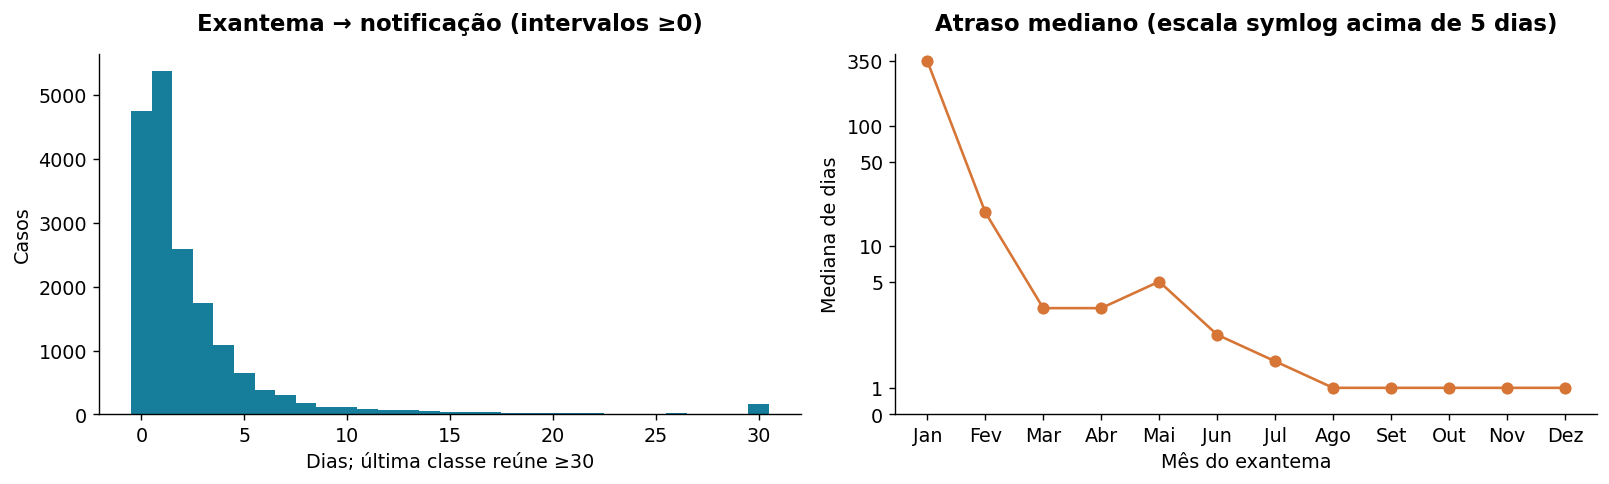

In [8]:
intervalos=coorte[['atraso','investigacao_dias','encerramento_dias']]
display(intervalos.describe(percentiles=[.25,.5,.75,.9,.95]).T)
atraso_valido=coorte.atraso[coorte.atraso.ge(0)]
fig,axs=plt.subplots(1,2,figsize=(13,4))
axs[0].hist(atraso_valido.clip(upper=30),bins=np.arange(-.5,31.5),color=AZUL)
axs[0].set(xlabel='Dias; última classe reúne ≥30',ylabel='Casos',title='Exantema → notificação (intervalos ≥0)')
coorte.assign(mes=coorte.DT_INICIO__data.dt.month).query('atraso >= 0').groupby('mes').atraso.median().reindex(range(1,13)).plot(ax=axs[1],marker='o',color=LARANJA)
axs[1].set_yscale('symlog',linthresh=5)
axs[1].set_ylim(0,400)
axs[1].set_yticks([0,1,5,10,50,100,350],labels=['0','1','5','10','50','100','350'])
axs[1].set(xticks=range(1,13),xticklabels=MESES,ylabel='Mediana de dias',xlabel='Mês do exantema',title='Atraso mediano (escala symlog acima de 5 dias)')
plt.tight_layout();plt.show()
print(f'Intervalos negativos: {(coorte.atraso<0).sum()}; mediana não negativa: {atraso_valido.median():.1f} dias; P90: {atraso_valido.quantile(.9):.1f} dias.')

Exantema anterior à data registrada de primeiros sintomas: 597
Exantemas de janeiro anteriores aos primeiros sintomas: 5
Registros excluídos nesta sensibilidade: 53
Pico na sensibilidade: 2019-08-11 ; casos: 1351


,casos,mediana_dias,maximo_dias,atraso_maior_60
DT_INICIO__data,,,,
1,6,350.50,369,5
2,11,19.00,247,5
3,18,4.00,187,7
4,34,4.00,155,8
5,87,5.00,125,6
6,618,3.00,94,10
7,3222,2.00,65,2
8,5616,1.00,72,2
9,4219,1.00,56,0


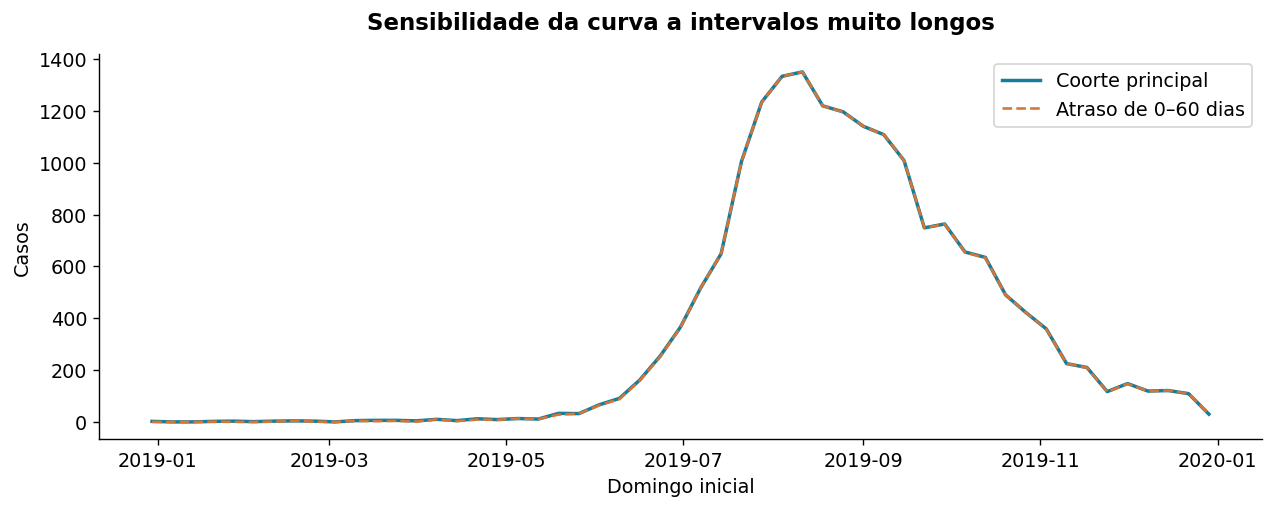

In [9]:
auditoria_mensal=coorte.groupby(coorte.DT_INICIO__data.dt.month).atraso.agg(casos='size',mediana_dias='median',maximo_dias='max',atraso_maior_60=lambda x:(x>60).sum())
display(auditoria_mensal)
coorte['exantema_menos_sintomas']=(coorte.DT_INICIO__data-coorte.DT_SIN_PRI_data).dt.days
print('Exantema anterior à data registrada de primeiros sintomas:',(coorte.exantema_menos_sintomas<0).sum())
print('Exantemas de janeiro anteriores aos primeiros sintomas:',((coorte.DT_INICIO__data.dt.month==1)&(coorte.exantema_menos_sintomas<0)).sum())
sem_atrasos_extremos=coorte[coorte.atraso.between(0,60)]
curva_sens=sem_atrasos_extremos.groupby('semana_inicio').size().reindex(semanas,fill_value=0)
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(curva.index,curva,label='Coorte principal',color=AZUL,lw=2)
ax.plot(curva_sens.index,curva_sens,label='Atraso de 0–60 dias',color=LARANJA,ls='--')
ax.set(xlabel='Domingo inicial',ylabel='Casos',title='Sensibilidade da curva a intervalos muito longos');ax.legend();plt.show()
print('Registros excluídos nesta sensibilidade:',N-len(sem_atrasos_extremos))
print('Pico na sensibilidade:',curva_sens.idxmax().date(),'; casos:',curva_sens.max())

**Anomalia relevante:** janeiro tem somente seis registros, mediana de atraso de 350,5 dias e cinco exantemas anteriores à data de primeiros sintomas. Esses registros não sustentam uma afirmação segura de transmissão em janeiro; podem envolver erro de digitação ou reconstrução retrospectiva. Há 597 registros com exantema anterior aos primeiros sintomas no conjunto. Não se corrigem datas por suposição.

A sensibilidade exclui 53 registros com atraso >60 dias. O limite é uma escolha de auditoria, não critério oficial de caso. A comparação mostra se a forma e o pico da curva persistem, preservando a coorte oficial como análise principal. Intervalos máximos de investigação e encerramento de vários anos também exigem cautela: podem refletir atualização tardia ou erros, não necessariamente a duração real do atendimento.

Os intervalos não negativos são usados apenas no gráfico de atraso; os negativos continuam no controle de qualidade. O último grupo do histograma reúne atrasos ≥30 dias, sem excluir a cauda. Diferenças mensais podem refletir poucos casos, investigação retrospectiva e mudanças de vigilância: não medem diretamente a qualidade de cada serviço.

## 5. Idade e sexo: frequência não é incidência

`NU_IDADE_N` codifica unidade e quantidade: milhares 1=horas, 2=dias, 3=meses, 4=anos. Decodificamos a unidade antes de criar as faixas; não interpretamos “4001” como 4.001 anos. Valores incompatíveis com a unidade são considerados desconhecidos. A idade é a registrada na notificação; não foi recalculada na data do exantema, o que pode afetar a faixa em registros muito tardios. Denominadores etários usam a mesma divisão de faixas da população processada.

Idade não interpretável: 0
Colunas da população por sexo: ['territorio', 'Masculino', 'Feminino', 'Total']
Sexo desconhecido: 3


,casos,populacao,incidencia,ic_inf,ic_sup,casos_%
<1 Ano,3285,590570,556.24,537.38,575.60,18.22
1-4,2580,2430473,106.15,102.10,110.33,14.31
5-9,458,3018173,15.17,13.82,16.63,2.54
10-14,320,3026655,10.57,9.45,11.80,1.78
15-19,2197,3245475,67.69,64.89,70.59,12.19
20-29,5591,6875736,81.31,79.20,83.47,31.02
30-39,2403,7438188,32.31,31.03,33.62,13.33
40-49,688,6509400,10.57,9.79,11.39,3.82
50-59,420,5403611,7.77,7.05,8.55,2.33
60-64,50,2163601,2.31,1.72,3.05,0.28


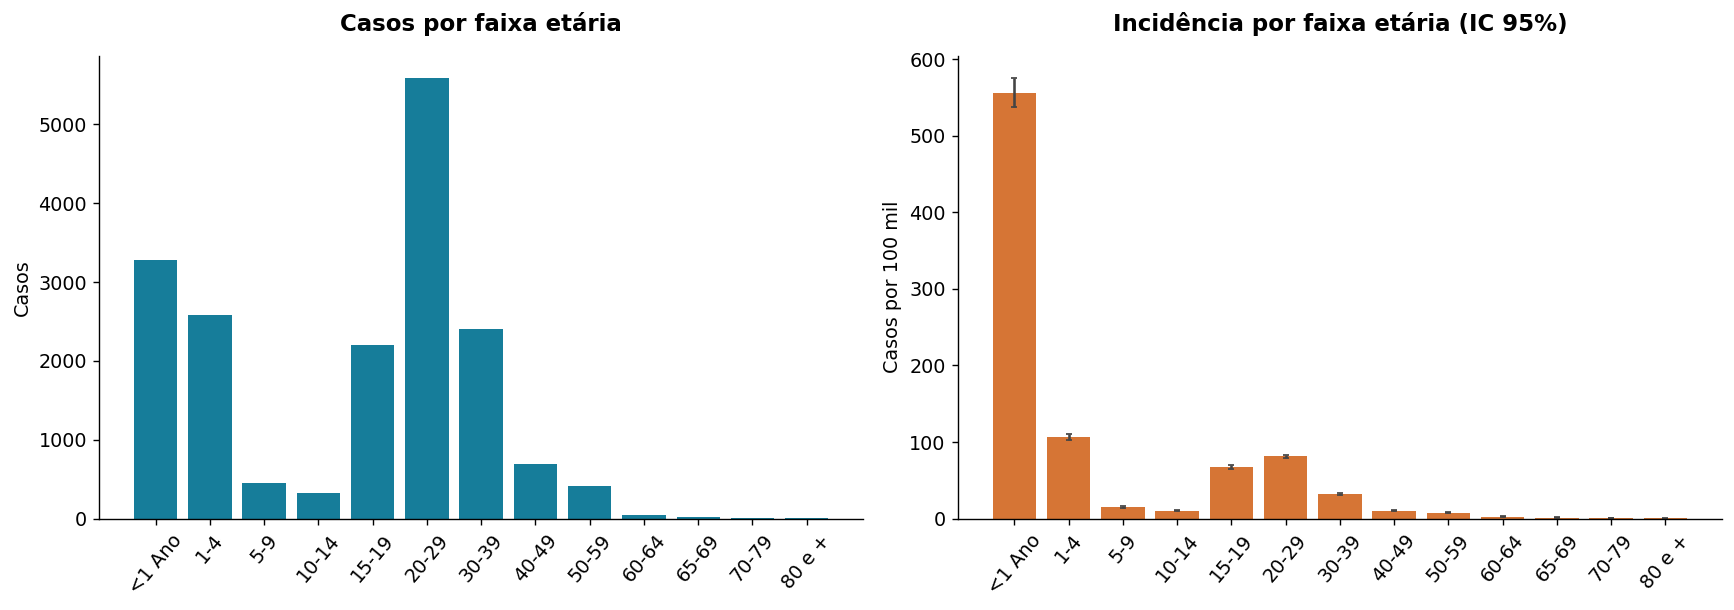

,casos,populacao,incidencia
CS_SEXO,,,
Masculino,9422,21982415,42.86
Feminino,8600,23323724,36.87


In [10]:
idade_cod=pd.to_numeric(coorte.NU_IDADE_N,errors='coerce')
unidade=idade_cod//1000; valor=idade_cod%1000
idade=pd.Series(np.nan,index=coorte.index)
idade.loc[unidade.eq(1)&valor.between(0,23)]=valor/24/365.25
idade.loc[unidade.eq(2)&valor.between(0,30)]=valor/365.25
idade.loc[unidade.eq(3)&valor.between(0,11)]=valor/12
idade.loc[unidade.eq(4)&valor.between(0,120)]=valor
coorte['idade']=idade
faixas=list(pop_idade.columns);limites_idade=[0,1,5,10,15,20,30,40,50,60,65,70,80,121]
coorte['faixa']=pd.cut(coorte.idade,limites_idade,right=False,labels=faixas)
perfil=pd.DataFrame({'casos':coorte.faixa.value_counts().reindex(faixas,fill_value=0),'populacao':pop_idade.sum()})
perfil['incidencia']=perfil.casos/perfil.populacao*1e5
perfil['ic_inf'],perfil['ic_sup']=ic_poisson(perfil.casos,perfil.populacao)
perfil['casos_%']=perfil.casos/N*100
display(perfil)
fig,axs=plt.subplots(1,2,figsize=(14,5))
axs[0].bar(faixas,perfil.casos,color=AZUL);axs[0].set_title('Casos por faixa etária');axs[0].set_ylabel('Casos')
axs[1].bar(faixas,perfil.incidencia,color=LARANJA);axs[1].errorbar(faixas,perfil.incidencia,yerr=[perfil.incidencia-perfil.ic_inf,perfil.ic_sup-perfil.incidencia],fmt='none',color='#444',capsize=2)
axs[1].set_title('Incidência por faixa etária (IC 95%)');axs[1].set_ylabel('Casos por 100 mil')
for ax in axs:ax.tick_params(axis='x',rotation=50)
plt.tight_layout();plt.show()
print('Idade não interpretável:',coorte.faixa.isna().sum())
print('Colunas da população por sexo:',list(pop_sexo.columns))
sexo=pd.DataFrame({'casos':coorte.CS_SEXO.value_counts().reindex(['M','F'],fill_value=0),
                  'populacao':[pop_sexo['Masculino'].sum(),pop_sexo['Feminino'].sum()]})
sexo['incidencia']=sexo.casos/sexo.populacao*1e5
display(sexo.rename(index={'M':'Masculino','F':'Feminino'}))
print('Sexo desconhecido:',(~coorte.CS_SEXO.isin(['M','F'])).sum())

A faixa de **20–29 anos** concentra **31.0% dos casos**, mas o maior coeficiente está nos **menores de 1 ano: 556.2 por 100 mil**. A concentração absoluta em adultos jovens e a incidência elevada em lactentes são achados complementares. Não é possível atribuir essas diferenças à vacinação apenas com a distribuição etária dos casos.

As comparações por sexo são brutas: diferenças de idade, exposição, procura por atendimento e registro podem contribuir. A variável do SINAN não descreve identidade de gênero.

## 6. Manifestações clínicas, confirmação e gravidade

Os percentuais de sintomas são apresentados entre todos os casos e entre registros conhecidos. Essa distinção evita que campos ignorados sejam tratados como ausência de sintomas. As notificações confirmadas não representam uma amostra aleatória de todas as infecções.

Hospitalizações: 2,249; 12.48% de todos; 13.79% dos conhecidos.
Óbitos pelo agravo: 18; letalidade registrada: 0.100%; entre evolução conhecida: 0.118%.


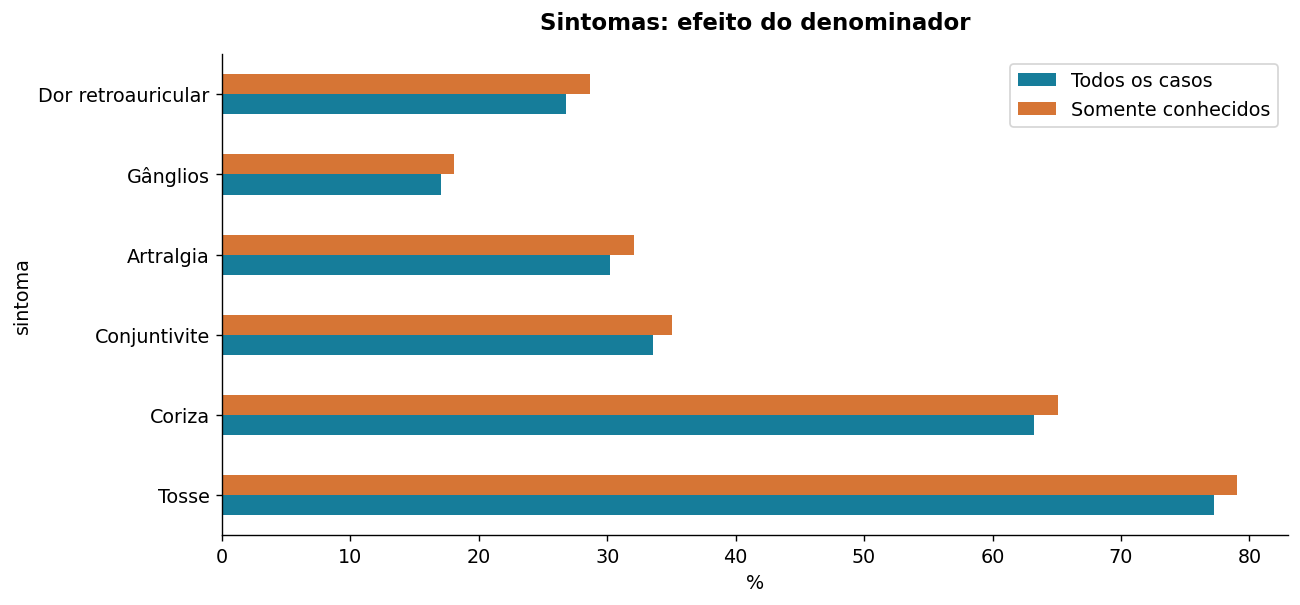

,sim,conhecidos,sim_%_todos,sim_%_conhecidos
sintoma,,,,
Tosse,13918,17612,77.21,79.03
Coriza,11403,17525,63.26,65.07
Conjuntivite,6056,17299,33.60,35.01
Artralgia,5445,16964,30.21,32.10
Gânglios,3073,17002,17.05,18.07
Dor retroauricular,4830,16847,26.80,28.67


,casos,percentual
CRITERIO,,
Laboratorial,13234,73.42
Vínculo epidemiológico,4289,23.79
Clínico,430,2.39
Desconhecido,62,0.34
Data da última dose,10,0.06


,casos,percentual
EVOLUCAO,,
Cura,15251,84.61
Desconhecido,2754,15.28
Óbito pelo agravo,18,0.10
Óbito por outra causa,2,0.01


,casos,hospitalizados,conhecidos,percentual_conhecidos,ic_inf,ic_sup,desconhecidos_%
faixa,,,,,,,
<1 Ano,3285,770,2966,25.96,24.41,27.57,9.71
1-4,2580,381,2343,16.26,14.82,17.81,9.19
5-9,458,46,427,10.77,8.17,14.07,6.77
10-14,320,24,294,8.16,5.55,11.86,8.12
15-19,2197,162,1986,8.16,7.03,9.44,9.60
20-29,5591,475,5053,9.40,8.63,10.24,9.62
30-39,2403,230,2178,10.56,9.34,11.92,9.36
40-49,688,84,618,13.59,11.11,16.52,10.17
50-59,420,64,370,17.30,13.78,21.48,11.90


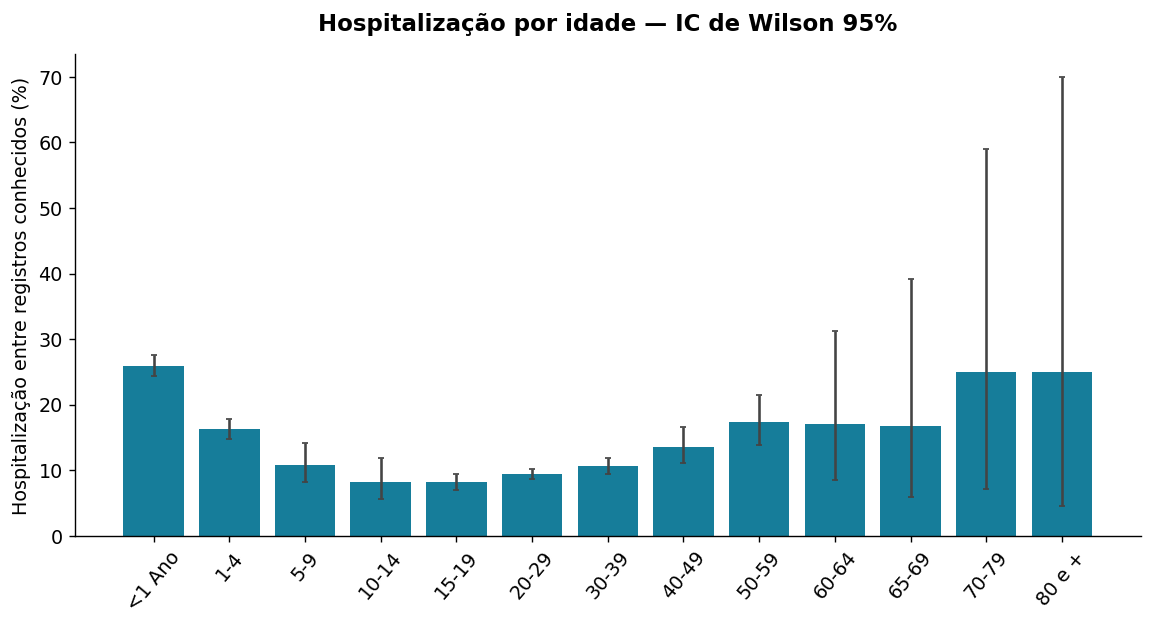

In [11]:
rotulos={'ID_TOSSE':'Tosse','ID_CORIZA':'Coriza','ID_CONJUNT':'Conjuntivite','ID_ARTRALG':'Artralgia','ID_GANGLIO':'Gânglios','ID_RETRO':'Dor retroauricular'}
sintomas=pd.DataFrame([{'sintoma':n,'sim':coorte[c].eq('1').sum(),'conhecidos':coorte[c].isin(['1','2']).sum()} for c,n in rotulos.items()]).set_index('sintoma')
sintomas['sim_%_todos']=sintomas.sim/N*100;sintomas['sim_%_conhecidos']=sintomas.sim/sintomas.conhecidos*100
sintomas[['sim_%_todos','sim_%_conhecidos']].plot.barh(color=[AZUL,LARANJA]);plt.xlabel('%');plt.title('Sintomas: efeito do denominador');plt.legend(['Todos os casos','Somente conhecidos']);plt.show()
display(sintomas)
criterio=coorte.CRITERIO.replace({'1':'Laboratorial','2':'Vínculo epidemiológico','3':'Clínico','4':'Data da última dose','':'Desconhecido'}).value_counts()
display(pd.DataFrame({'casos':criterio,'percentual':criterio/N*100}))
evolucao=coorte.EVOLUCAO.replace({'1':'Cura','2':'Óbito pelo agravo','3':'Óbito por outra causa','9':'Desconhecido','':'Desconhecido'}).value_counts()
display(pd.DataFrame({'casos':evolucao,'percentual':evolucao/N*100}))
hosp=coorte.ID_HOSPIT.eq('1').sum();hosp_conhecido=coorte.ID_HOSPIT.isin(['1','2']).sum()
obitos=coorte.EVOLUCAO.eq('2').sum();evol_conhecida=coorte.EVOLUCAO.isin(['1','2','3']).sum()
print(f'Hospitalizações: {hosp:,}; {100*hosp/N:.2f}% de todos; {100*hosp/hosp_conhecido:.2f}% dos conhecidos.')
print(f'Óbitos pelo agravo: {obitos}; letalidade registrada: {100*obitos/N:.3f}%; entre evolução conhecida: {100*obitos/evol_conhecida:.3f}%.')
hosp_idade=coorte.groupby('faixa',observed=False).agg(casos=('ID_HOSPIT','size'),hospitalizados=('ID_HOSPIT',lambda s:s.eq('1').sum()),conhecidos=('ID_HOSPIT',lambda s:s.isin(['1','2']).sum()))
hosp_idade['percentual_conhecidos']=hosp_idade.hospitalizados/hosp_idade.conhecidos*100
hosp_idade['ic_inf'],hosp_idade['ic_sup']=wilson(hosp_idade.hospitalizados,hosp_idade.conhecidos)
hosp_idade['desconhecidos_%']=(hosp_idade.casos-hosp_idade.conhecidos)/hosp_idade.casos*100
display(hosp_idade)
plt.bar(faixas,hosp_idade.percentual_conhecidos,color=AZUL)
plt.errorbar(faixas,hosp_idade.percentual_conhecidos,yerr=[hosp_idade.percentual_conhecidos-hosp_idade.ic_inf,hosp_idade.ic_sup-hosp_idade.percentual_conhecidos],fmt='none',color='#444',capsize=2)
plt.xticks(rotation=50);plt.ylabel('Hospitalização entre registros conhecidos (%)');plt.title('Hospitalização por idade — IC de Wilson 95%');plt.show()

Há **2.249 hospitalizações registradas** e **18 óbitos atribuídos ao agravo**. A letalidade registrada é aproximadamente **0,10%**, calculada sobre todos os casos da coorte. A evolução desconhecida impede tratar essa estimativa como risco definitivo de morrer por infecção. O cálculo entre evoluções conhecidas é uma sensibilidade, não uma correção válida se os dados faltantes forem seletivos.

As proporções de hospitalização não equivalem à gravidade biológica isolada: também dependem de acesso e decisões de internação. Os intervalos de Wilson mostram a imprecisão por faixa, mas não corrigem informação ausente. Contagens pequenas de óbitos não justificam modelos multivariados complexos neste trabalho.

## 7. Vacinação individual e bloqueio vacinal

O antecedente vacinal e a cobertura municipal respondem a perguntas diferentes. O primeiro descreve os casos notificados; a segunda é um indicador administrativo de rotina infantil. Nenhuma das duas medidas, sozinha, fornece o denominador de pessoas expostas necessário para estimar efetividade vacinal.

Vacina=sim, última dose posterior ao exantema: 255
Vacina=sim, última dose 0–13 dias antes do exantema: 1307


,casos,percentual
CS_VACINA,,
Sim,7373,40.90
Não,7408,41.10
Ignorado,3244,18.00


,registros,percentual
CS_VACINAL,,
Realizado,10253,56.88
Todos vacinados,3028,16.80
Não realizado,2508,13.91
Ignorado,2155,11.96
Sem história de contato,81,0.45


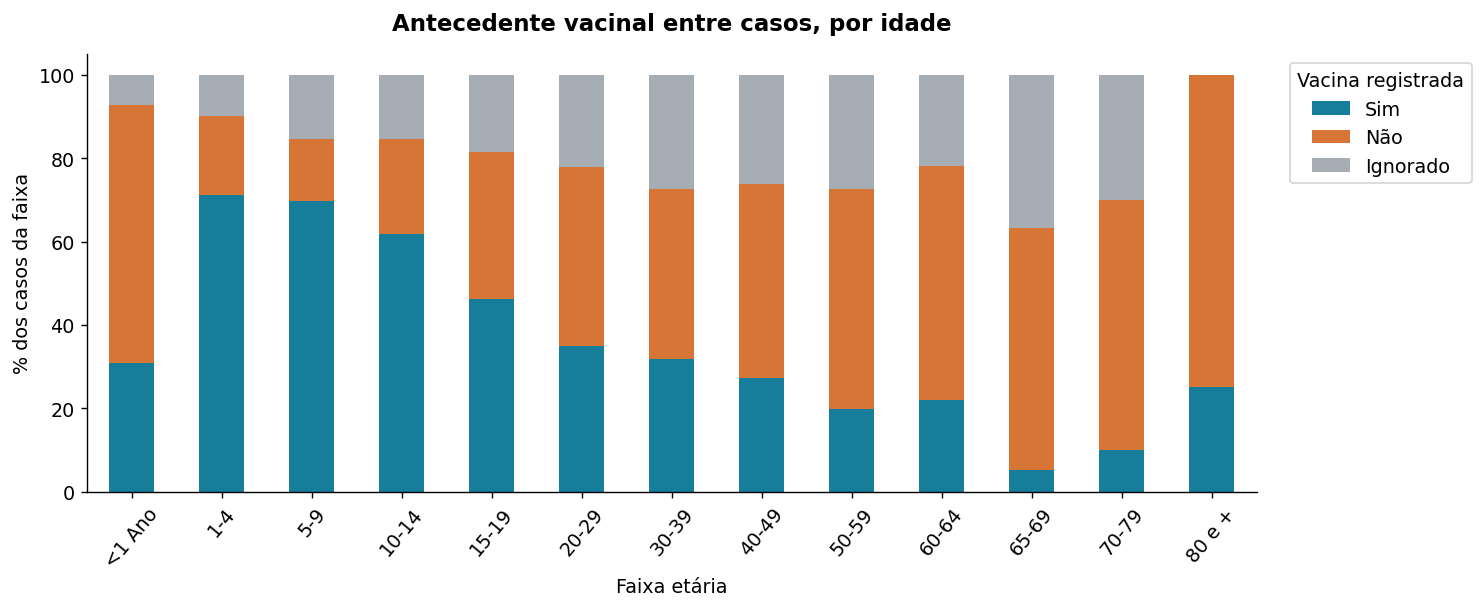

In [12]:
antecedente=coorte.CS_VACINA.replace({'1':'Sim','2':'Não','9':'Ignorado','':'Ignorado'}).value_counts().reindex(['Sim','Não','Ignorado'],fill_value=0)
display(pd.DataFrame({'casos':antecedente,'percentual':antecedente/N*100}))
bloqueio=coorte.CS_VACINAL.replace({'1':'Realizado','2':'Não realizado','3':'Todos vacinados','4':'Sem história de contato','9':'Ignorado','':'Ignorado'}).value_counts()
display(pd.DataFrame({'registros':bloqueio,'percentual':bloqueio/N*100}))
cruzamento=pd.crosstab(coorte.faixa,coorte.CS_VACINA.replace({'1':'Sim','2':'Não','9':'Ignorado','':'Ignorado'}),dropna=False).reindex(faixas)
(cruzamento.div(cruzamento.sum(axis=1),axis=0)*100).reindex(columns=['Sim','Não','Ignorado']).plot.bar(stacked=True,color=[AZUL,LARANJA,CINZA],figsize=(12,5))
plt.ylabel('% dos casos da faixa');plt.xlabel('Faixa etária');plt.xticks(rotation=50);plt.title('Antecedente vacinal entre casos, por idade');plt.legend(title='Vacina registrada',bbox_to_anchor=(1.02,1),loc='upper left');plt.tight_layout();plt.show()
ultima=(coorte.DT_INICIO__data-coorte.DT_DOSE_N_data).dt.days
print('Vacina=sim, última dose posterior ao exantema:',int((coorte.CS_VACINA.eq('1') & ultima.lt(0)).sum()))
print('Vacina=sim, última dose 0–13 dias antes do exantema:',int((coorte.CS_VACINA.eq('1') & ultima.between(0,13)).sum()))

A presença de casos com vacinação registrada não demonstra ineficácia da vacina. Faltam população vacinada e não vacinada comparáveis, número de doses, oportunidade da vacinação e validação do histórico. Uma dose após o exantema não caracteriza proteção prévia; uma dose próxima ao início também exige contexto. Os intervalos de 0–13 dias são apenas uma auditoria temporal, não uma reclassificação clínica.

O bloqueio é registrado por ficha: somar fichas com bloqueio não fornece o número de campanhas, ações independentes ou pessoas imunizadas. O notebook não atribui a queda da curva ao bloqueio, pois não há desenho causal nem datas e exposição suficientes.

## 8. Cobertura vacinal municipal antes da epidemia (2016–2018)

A proveniência recebida associa os indicadores históricos 021 e 098 à primeira e à segunda dose (D1 e D2). Há um valor por município, ano e dose. A cobertura administrativa pode ultrapassar 100%; isso indica incompatibilidade entre doses contabilizadas e população-alvo, não mais de 100% de pessoas protegidas. Mantemos os valores originais e comparamos resultados com e sem os valores acima de 100%.

Valores >100%: 1380 / 3870
D2 maior que D1 em 2018: 96 municípios


n  minimo  mediana  maximo  acima_100  acima_200
year dose                                                    
2016 MMR1  645    0.00   100.35  360.00        325         15
     MMR2  645    0.00    85.90  256.00        187          6
2017 MMR1  645    0.00    95.71  440.00        270         17
     MMR2  645    0.00    87.08  280.00        176          7
2018 MMR1  645    2.54    96.23  274.29        268          8
     MMR2  645    2.54    86.67  226.32        154          2

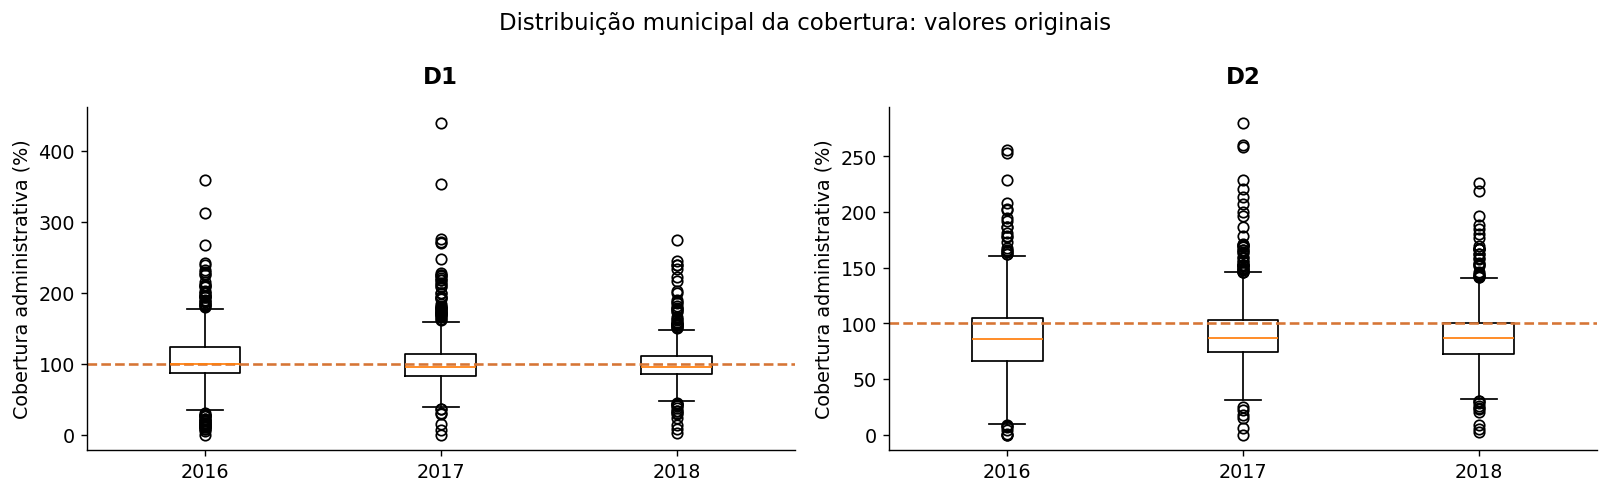

In [13]:
vacinas['codigo']=vacinas.municipality_ibge.str[:6]
assert len(vacinas)==645*3*2 and not vacinas.duplicated(['codigo','year','dose']).any()
assert vacinas.coverage_percent.notna().all() and set(vacinas.codigo)==set(municipios.index)
qa_vac=vacinas.groupby(['year','dose']).coverage_percent.agg(n='size',minimo='min',mediana='median',maximo='max',acima_100=lambda x:(x>100).sum(),acima_200=lambda x:(x>200).sum())
display(qa_vac)
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,dose in zip(axs,['MMR1','MMR2']):
    dados=[vacinas.loc[(vacinas.year==ano)&(vacinas.dose==dose),'coverage_percent'] for ano in [2016,2017,2018]]
    ax.boxplot(dados,tick_labels=['2016','2017','2018'],showfliers=True)
    ax.axhline(100,color=LARANJA,ls='--',label='100%');ax.set_title('D1' if dose=='MMR1' else 'D2');ax.set_ylabel('Cobertura administrativa (%)')
plt.suptitle('Distribuição municipal da cobertura: valores originais');plt.tight_layout();plt.show()
painel=vacinas.pivot(index='codigo',columns=['year','dose'],values='coverage_percent')
municipios['d1_2018']=painel[(2018,'MMR1')];municipios['d2_2018']=painel[(2018,'MMR2')]
municipios['d2_media_16_18']=painel.loc[:,[(2016,'MMR2'),(2017,'MMR2'),(2018,'MMR2')]].mean(axis=1)
print('Valores >100%:',(vacinas.coverage_percent>100).sum(),'/',len(vacinas))
print('D2 maior que D1 em 2018:',(municipios.d2_2018>municipios.d1_2018).sum(),'municípios')

Os **1.380 valores acima de 100% (35,7%)**, entre 3.870 observações, limitam fortemente interpretações literais. A mediana municipal atribui o mesmo peso a uma cidade pequena e à capital; não é cobertura estadual ponderada. Não calculamos cobertura estadual a partir dessas porcentagens sem os denominadores específicos da população-alvo.

A diferença D1–D2 no mesmo ano não mede diretamente abandono entre doses: as populações elegíveis e o calendário diferem. A média 2016–2018 abaixo resume valores administrativos por município, sem representar uma coorte acompanhada.

## 9. Associações ecológicas: vacinação, densidade e PIB

Análise exploratória por município, com todos os 645 municípios, inclusive os sem casos. Usamos correlação de Spearman para relações monotônicas; cada município recebe peso igual. A associação entre cobertura infantil e incidência em todas as idades tem um descompasso de população-alvo. Por isso, acrescentamos a incidência de 1–4 anos como comparação, ainda imperfeita.

Não se trata de um teste de efetividade: densidade, mobilidade, importações, idade, serviços e subnotificação podem confundir os resultados. A dependência espacial viola a independência usual dos testes; não usamos p-valores como prova causal.

,recorte,desfecho,n,rho_Spearman
0,Todos,incidencia,645,-0.18
1,Todos,incidencia_1a4,645,-0.15
2,Todos,sir,645,-0.18
3,D2 entre 0 e 100,incidencia,491,-0.10
4,D2 entre 0 e 100,incidencia_1a4,491,-0.06
5,D2 entre 0 e 100,sir,491,-0.10
6,População ≥20 mil,incidencia,254,-0.21
7,População ≥20 mil,incidencia_1a4,254,-0.13
8,População ≥20 mil,sir,254,-0.21
9,Sem a capital,incidencia,644,-0.18


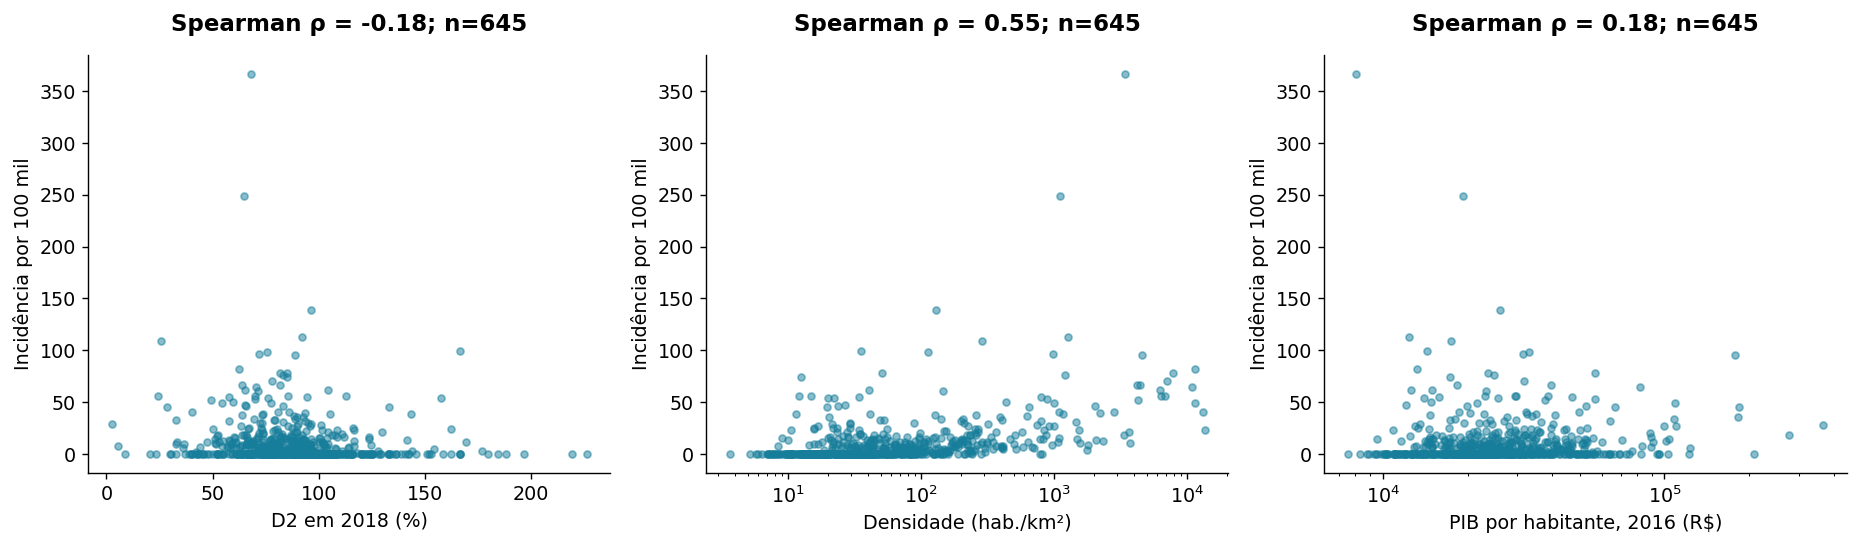

,variavel,n,rho
0,d1_2018,645,-0.20
1,d2_2018,645,-0.18
2,d2_media_16_18,645,-0.19
3,densidade,645,0.55
4,pib_pc_2016,645,0.18


In [14]:
pib['codigo']=pib.municipality_ibge.str[:6]
assert pib.codigo.is_unique
municipios=municipios.join(pib.set_index('codigo')[['gdp_per_capita_brl_2016']],validate='one_to_one').rename(columns={'gdp_per_capita_brl_2016':'pib_pc_2016'})
cont_1a4=coorte.loc[coorte.faixa.eq('1-4'),'ID_MN_RESI'].value_counts().reindex(municipios.index,fill_value=0)
municipios['incidencia_1a4']=cont_1a4/pop_idade['1-4']*1e5
esperados=pop_idade.mul(perfil.casos/perfil.populacao,axis=1).sum(axis=1)
municipios['sir']=municipios.casos/esperados
linhas=[]
for nome,mascara in [('Todos',pd.Series(True,index=municipios.index)),('D2 entre 0 e 100',municipios.d2_2018.between(0,100)),('População ≥20 mil',municipios.populacao.ge(20000)),('Sem a capital',municipios.index!='355030')]:
    sub=municipios.loc[mascara]
    for desfecho in ['incidencia','incidencia_1a4','sir']:
        par=sub[['d2_2018',desfecho]].dropna()
        linhas.append({'recorte':nome,'desfecho':desfecho,'n':len(par),'rho_Spearman':spearmanr(par.d2_2018,par[desfecho]).statistic})
correlacoes=pd.DataFrame(linhas);display(correlacoes)
fig,axs=plt.subplots(1,3,figsize=(15,4.5))
for ax,x,label in zip(axs,['d2_2018','densidade','pib_pc_2016'],['D2 em 2018 (%)','Densidade (hab./km²)','PIB por habitante, 2016 (R$)']):
    ax.scatter(municipios[x],municipios.incidencia,s=16,alpha=.5,color=AZUL)
    if x!='d2_2018':ax.set_xscale('log')
    ax.set_xlabel(label);ax.set_ylabel('Incidência por 100 mil')
    par=municipios[[x,'incidencia']].dropna();rho=spearmanr(par[x],par.incidencia).statistic
    ax.set_title(f'Spearman ρ = {rho:.2f}; n={len(par)}')
plt.tight_layout();plt.show()
sens=[]
for v in ['d1_2018','d2_2018','d2_media_16_18','densidade','pib_pc_2016']:
    par=municipios[[v,'incidencia']].dropna();sens.append({'variavel':v,'n':len(par),'rho':spearmanr(par[v],par.incidencia).statistic})
display(pd.DataFrame(sens))

A correlação bruta entre D2 de 2018 e incidência de 2019 é **ρ=-0.184**; restringindo a cobertura a 0–100%, passa a **ρ=-0.099**. A tabela mostra como ela muda com o desfecho e o recorte. A associação é fraca e se atenua ao remover valores administrativamente problemáticos. A densidade tem correlação positiva de **ρ≈0,55** e o PIB por habitante de **ρ≈0,18**. Maior densidade pode acompanhar maior oportunidade de contato, conectividade ou melhor detecção; esta análise não separa esses mecanismos.

Esses resultados quantificam a associação observada, mas não isolam proteção individual nem demonstram ausência de efeito vacinal.

A **SIR** divide casos observados pelos esperados usando taxas etárias estaduais e a população local: é uma padronização indireta, não um risco causal ajustado. A estrutura etária é parcialmente considerada; mobilidade, história de transmissão e outros confundidores permanecem. PIB por habitante é produção econômica média municipal, podendo ser alto em municípios industriais sem que toda a população tenha renda elevada. Uma associação municipal não pode ser transferida automaticamente para indivíduos (falácia ecológica).

## 10. Sensibilidades e limites de robustez

Três escolhas são avaliadas explicitamente: fonte populacional, critério de confirmação e data usada no recorte. São análises alternativas, não conjuntos a somar. O recorte por primeiros sintomas é mostrado apenas para documentar que datas diferentes produzem totais distintos.

In [15]:
sensibilidade=pd.DataFrame([
 {'definicao':'Principal: exantema 2019, dois arquivos','casos':N,'populacao':POP},
 {'definicao':'Mesmo numerador, população IBGE alternativa','casos':N,'populacao':municipios.pop_original.sum()},
 {'definicao':'Apenas confirmação laboratorial','casos':coorte.CRITERIO.eq('1').sum(),'populacao':POP},
 {'definicao':'Somente arquivo 2019 (perde tardios)','casos':coorte.arquivo.eq('EXANBR19.dbc').sum(),'populacao':POP},
 {'definicao':'Primeiros sintomas 2019, dois arquivos','casos':confirmados.DT_SIN_PRI_data.dt.year.eq(2019).sum(),'populacao':POP}])
sensibilidade['por_100_mil']=sensibilidade.casos/sensibilidade.populacao*1e5
display(sensibilidade)
municipios['incidencia_pop_alternativa']=municipios.casos/municipios.pop_original*1e5
print('Correlação dos rankings de incidência com dois denominadores:',round(spearmanr(municipios.incidencia,municipios.incidencia_pop_alternativa).statistic,4))
print('Casos tardios recuperados:',coorte.arquivo.eq('EXANBR20.dbc').sum())
# Auditorias finais: reconciliação dos totais, integridade das junções e domínio dos indicadores.
assert municipios.casos.sum()==N==mensal.sum()==curva.sum()
assert perfil.casos.sum()+coorte.faixa.isna().sum()==N
assert len(municipios)==645 and municipios.index.is_unique
assert municipios[['populacao','pop_original','area_km2']].gt(0).all().all()
assert municipios[['pib_pc_2016','d2_2018']].notna().all().all()
assert np.isclose(pop_idade.to_numpy().sum(),POP)
assert all(len(c)==6 for c in municipios.index)
print('Auditorias concluídas: totais reconciliados, códigos únicos, denominadores positivos e junções completas.')

Correlação dos rankings de incidência com dois denominadores: 0.9997
Casos tardios recuperados: 55
Auditorias concluídas: totais reconciliados, códigos únicos, denominadores positivos e junções completas.


,definicao,casos,populacao,por_100_mil
0,"Principal: exantema 2019, dois arquivos",18025,"45,306,139.00",39.78
1,"Mesmo numerador, população IBGE alternativa",18025,"45,919,049.00",39.25
2,Apenas confirmação laboratorial,13234,"45,306,139.00",29.21
3,Somente arquivo 2019 (perde tardios),17970,"45,306,139.00",39.66
4,"Primeiros sintomas 2019, dois arquivos",18132,"45,306,139.00",40.02


A restrição laboratorial aumenta a especificidade operacional do recorte, mas pode excluir casos epidemiologicamente confirmados e mudar a representatividade. Não é automaticamente uma estimativa melhor do tamanho da epidemia. A alternativa populacional muda o coeficiente, não o número de casos.

**Limites que permanecem:**

- Subnotificação e seleção de casos mais sintomáticos; incidência de notificações confirmadas não equivale à incidência de todas as infecções.
- Dados ignorados, inconsistências temporais e ausência de identificador individual para auditoria definitiva de duplicidades.
- Arquivos de notificação limitados a 2019–2020. A concordância com o total TabNet anterior é um controle útil, não prova de completude absoluta.
- Coberturas administrativas com valores >100%, obtidas de um espelho segundo a proveniência, sem auditoria independente de todas as doses e populações-alvo.
- Cobertura de rotina infantil não representa imunidade de adolescentes e adultos. Faltam cobertura por idade, histórico de doses e campanhas detalhadas.
- PIB de 2016 e população revisada de 2019 têm referências distintas; dependência espacial e confundimento impedem conclusões causais.
- Não há dados suficientes para reconstruir cadeias de transmissão, estimar efetividade vacinal ou atribuir a redução dos casos às intervenções. Não estimamos Rₜ com suposições não validadas sobre atrasos, importações e intervalo de geração.

A seção 13 avalia explicitamente se o clustering acrescenta uma tipologia útil aos gráficos simples, com controles de estabilidade e sensibilidade. Os grupos são descrições retrospectivas, não explicações causais.

## 11. Conclusões da caracterização descritiva

1. A integração de EXANBR19 e EXANBR20 identifica **18.025 casos de residentes paulistas com exantema em 2019**, incluindo **55 notificações de 2020**. O uso da data original resolve a principal limitação temporal da tabulação anterior.
2. A incidência estadual é **39.78 por 100 mil habitantes**. Os casos se distribuem por **307 municípios**, com forte concentração numérica na capital e grandes diferenças nas incidências municipais.
3. Adultos de 20–29 anos concentram o maior volume, enquanto menores de 1 ano apresentam a maior incidência. Planejamento baseado somente em contagens perderia essa diferença de risco registrado.
4. A base permite caracterizar **2.249 hospitalizações** e **18 óbitos pelo agravo**, mas a incompletude de evolução e hospitalização limita a precisão das proporções.
5. A vacinação pode ser analisada em dois níveis: histórico dos casos e cobertura municipal anterior. Os resultados ecológicos são exploratórios e sensíveis à qualidade administrativa; não estimam efeito causal ou efetividade.

**O que os dados sustentam:** descrição verificável da concentração temporal, territorial e etária, dimensionamento da carga registrada e identificação de limitações da vigilância. **O que não sustentam:** afirmar que uma característica municipal causou a epidemia, que a vacina falhou ou que uma intervenção específica encerrou a transmissão.

Não falta nenhum arquivo indispensável para esta caracterização descritiva. Para ampliar a investigação causal, seriam necessários denominadores vacinais por idade, histórico de doses, dados de intervenções e exposição, além de melhor auditoria dos registros.

### Reprodutibilidade da etapa descritiva

Todas as tabelas e figuras são recalculadas a partir de `data/processed`. O script `scripts/prepare_data.py` reconstrói esses arquivos usando somente `data/raw`, sem baixar dados. A leitura no notebook verifica os hashes SHA-256 das fontes e dos derivados. Os filtros e transformações ficam visíveis; as versões e limitações estão documentadas em `FONTES.md`. A publicação do projeto também publica os campos dos microdados selecionados e os DBC recebidos, embora os arquivos analisados não contenham nomes ou endereços.

In [16]:
import scipy, matplotlib
print('Python:',sys.version.split()[0])
print('pandas:',pd.__version__,'| numpy:',np.__version__,'| scipy:',scipy.__version__,'| matplotlib:',matplotlib.__version__)
print('Análise concluída. Dados lidos de data/processed; preparação reproduzível em scripts/prepare_data.py.')

Python: 3.12.14
pandas: 2.2.3 | numpy: 2.3.5 | scipy: 1.17.0 | matplotlib: 3.10.8
Análise concluída. Dados lidos de data/processed; preparação reproduzível em scripts/prepare_data.py.


## 12. Machine learning: previsão espacial da incidência municipal

### 12.1 Pergunta e desenho do estudo

**Pergunta:** indicadores demográficos, econômicos e vacinais conseguem prever o número de casos em municípios de uma região cujos casos não participaram do treinamento? A vacinação acrescenta informação além da demografia e do PIB?

São **645 observações municipais**, incluindo os 338 municípios sem casos. A variável-alvo é a contagem de casos com exantema em 2019. A população entra como exposição: comparamos contagens esperadas levando em conta o tamanho municipal. Não usamos contagem, hospitalização, mortes, atraso de notificação, SIR ou qualquer outro desfecho de 2019 como preditor.

**É uma avaliação retrospectiva de transferência espacial, não uma previsão prospectiva de 2019.** Vacinação refere-se a 2016–2018 e PIB a 2016, mas os denominadores demográficos são revisões de 2019 recuperadas posteriormente. Não temos versões congeladas de tudo que estava disponível antes da epidemia. O teste em outra região do mesmo ano não demonstra capacidade de prever uma epidemia futura.

O protocolo e as pequenas grades de parâmetros foram definidos antes da leitura dos resultados. Nenhum dado de teste orienta a imputação, padronização ou escolha de hiperparâmetros. A comparação final de modelos é exploratória; o menor erro observado não constitui validação externa independente de um “campeão”.

### 12.2 Variáveis e modelos

| Conjunto | Variáveis |
|---|---|
| Demografia | Log da densidade; frações de 0–4, 5–19, 20–39 e ≥60 anos. A faixa 40–59 fica como referência para evitar soma perfeita |
| Economia | Log do PIB por habitante de 2016 |
| Vacinação | Média 2016–2018 de D1 e D2; diferença 2018−2016 para cada dose; fração das seis coberturas que ultrapassa 100% |

A fração >100% é um indicador da anomalia administrativa, não de imunidade. No cenário de sensibilidade, limitamos as coberturas a 100% **somente para calcular médias e diferenças**; preservamos o indicador de anomalia original e todos os municípios. Isso é uma transformação de sensibilidade, não correção comprovada dos dados.

| Modelo | Configuração |
|---|---|
| Referência populacional | Incidência agregada do treino × população do município de teste |
| Poisson demografia | Demografia, ligação log, regularização L2 |
| Poisson + PIB | Demografia + economia |
| Poisson + PIB + vacina | Todos os conjuntos; comparação direta com o anterior |
| Binomial negativa completa | Todos os conjuntos; variância μ + αμ², offset populacional, L2 fixa 0,1 |
| Boosting sem/com vacina | Árvores pequenas, perda Poisson; duas versões para testar contribuição incremental |

Poisson usa taxa por 100 mil como resposta e população/100 mil como peso. Sem penalização, isso é equivalente à formulação de contagens com offset `log(população/100 mil)`; a escala da penalização é explicitamente mantida no código. O boosting usa a mesma resposta e ponderação. A binomial negativa ajusta diretamente a contagem com offset.

Grades internas: L2 de Poisson ∈ {0,1; 1; 10}; dispersão α da binomial negativa ∈ {0,1; 1; 10}, selecionada por validação, não estimada por máxima verossimilhança; folhas do boosting ∈ {3; 7}, 100 iterações, taxa 0,05, mínimo 20 observações por folha, L2=10, sem parada antecipada. Não há busca extensa que possa explorar acidentalmente o teste.

Referências de implementação: [Poisson e exposição — scikit-learn](https://scikit-learn.org/stable/auto_examples/linear_model/plot_tweedie_regression_insurance_claims.html), [HistGradientBoostingRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html), [GLM e binomial negativa — statsmodels](https://www.statsmodels.org/stable/glm.html).

In [17]:
# Os cálculos estão em scripts/modelagem.py; resultados auditáveis em results/ml.
import importlib
from pathlib import Path
sys.path.insert(0, str(ROOT / 'scripts'))
import modelagem
importlib.reload(modelagem)
ML = ROOT / 'results' / 'ml'
RECALCULAR_ML = False  # True: refaz todos os ajustes e sobrescreve os resultados.
meta_path = ML / 'execucao.json'
cache_valido = False
if meta_path.exists():
    meta_ml = json.loads(meta_path.read_text(encoding='utf-8'))
    cache_valido = meta_ml['assinatura_entradas'] == modelagem.assinatura_entradas()
    cache_valido = cache_valido and all((ML/nome).exists() and hashlib.sha256((ML/nome).read_bytes()).hexdigest()==sha
                                      for nome,sha in meta_ml['arquivos_resultados'].items())
if RECALCULAR_ML or not cache_valido:
    modelagem.rodar_tudo(ML)
meta_ml=json.loads(meta_path.read_text(encoding='utf-8'))
base_ml=pd.read_csv(ML/'base_municipal_ml.csv',dtype={'codigo':str}).set_index('codigo')
metricas_ml=pd.read_csv(ML/'metricas.csv')
folds_ml=pd.read_csv(ML/'folds.csv')
pred_ml=pd.read_csv(ML/'predicoes.csv',dtype={'codigo':str})
ajustes_ml=pd.read_csv(ML/'ajustes.csv')
perm_ml=pd.read_csv(ML/'permutacao.csv')
dispersao_ml=pd.read_csv(ML/'dispersao.csv')
sem_capital_ml=pd.read_csv(ML/'metricas_sem_capital.csv')
print('645 municípios; sete modelos; três divisões de teste e uma sensibilidade vacinal.')
print('Versões usadas no treinamento:',meta_ml['versoes'])
print('Hashes dos dados, script e resultados verificados. Recalcular:',RECALCULAR_ML)
display(base_ml[modelagem.SOC+modelagem.VAC].describe().T)

645 municípios; sete modelos; três divisões de teste e uma sensibilidade vacinal.
Versões usadas no treinamento: {'scikit-learn': '1.8.0', 'statsmodels': '0.15.0', 'pandas': '2.2.3', 'numpy': '2.3.5', 'scipy': '1.17.0'}
Hashes dos dados, script e resultados verificados. Recalcular: False


,count,mean,std,min,25%,50%,75%,max
log_densidade,645.00,4.07,1.47,1.30,3.02,3.71,4.80,9.52
frac_0a4,645.00,0.07,0.01,0.02,0.06,0.07,0.07,0.09
frac_5a19,645.00,0.21,0.02,0.08,0.19,0.21,0.22,0.26
frac_20a39,645.00,0.30,0.03,0.22,0.28,0.30,0.31,0.59
frac_60mais,645.00,0.17,0.03,0.08,0.14,0.16,0.19,0.30
log_pib,645.00,10.16,0.54,8.93,9.81,10.10,10.44,12.81
d1_media,645.00,102.83,26.92,19.26,87.84,98.95,114.65,311.11
d2_media,645.00,88.44,24.84,17.45,73.83,87.04,100.41,221.14
d1_delta,645.00,-5.64,42.91,-226.67,-23.89,-4.88,14.37,225.71
d2_delta,645.00,1.00,36.64,-157.09,-18.99,1.64,20.55,120.00


### 12.3 Validação espacial aninhada e mudança de distribuição

**Avaliação principal:** cinco blocos definidos por k-means das coordenadas geográficas aproximadas dos municípios, semente 42. O ponto de cada município é o centro da sua caixa envolvente; a longitude é ajustada pelo cosseno da latitude média. Não são centroides populacionais nem regiões administrativas oficiais. O agrupamento usa apenas localização, nunca casos ou vacinação.

Em cada rodada externa, um bloco inteiro é reservado para teste. Nos quatro blocos restantes, fazemos validação interna deixando um bloco de fora por vez. Cada transformação aprende apenas no respectivo treino. O parâmetro com menor desvio Poisson interno ponderado pelo número de municípios é escolhido; o modelo é reajustado nos quatro blocos e avaliado no quinto.

**Sensibilidades:** cinco faixas de longitude com tamanhos semelhantes e uma divisão aleatória de cinco partes. No cenário aleatório, o ajuste interno usa três partes aleatórias; portanto, o contraste inclui mudança tanto no teste como no procedimento de ajuste. É um diagnóstico de sensibilidade do protocolo, não uma estimativa isolada do efeito da proximidade.

Não há faixa de exclusão entre blocos: municípios vizinhos podem estar em lados opostos de uma fronteira. A dependência espacial não desaparece; a separação por grandes áreas é mais exigente que a aleatória, mas não garante independência completa. A mesma geometria pode ser usada para definir os blocos sem vazamento do alvo.

,municipios,casos,populacao,incidencia,casos_%,incidencia_treino
bloco,,,,,,
1,115,132,1921232,6.87,0.73,41.24
2,117,296,2118650,13.97,1.64,41.05
3,120,261,3515024,7.43,1.45,42.51
4,133,300,4712745,6.37,1.66,43.66
5,160,17036,33038488,51.56,94.51,8.06


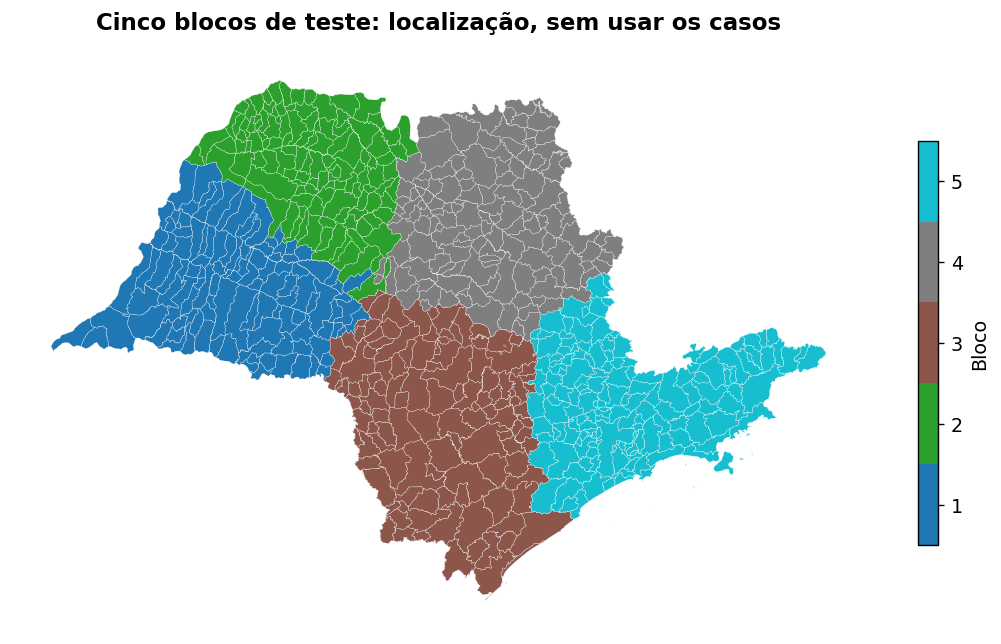

In [18]:
blocos=base_ml.groupby('bloco').agg(municipios=('casos','size'),casos=('casos','sum'),populacao=('populacao','sum'))
blocos['incidencia']=blocos.casos/blocos.populacao*1e5
blocos['casos_%']=blocos.casos/base_ml.casos.sum()*100
blocos['incidencia_treino']=(base_ml.casos.sum()-blocos.casos)/(base_ml.populacao.sum()-blocos.populacao)*1e5
display(blocos)
fig,ax=plt.subplots(figsize=(11,6));vertices=[];cores=[]
for cod,partes in malha.items():
    for parte in partes:
        vertices.append(np.asarray(parte));cores.append(base_ml.loc[cod,'bloco'])
pc=PolyCollection(vertices,array=np.asarray(cores),cmap=plt.get_cmap('tab10',5),clim=(.5,5.5),edgecolors='white',linewidths=.15)
ax.add_collection(pc);ax.autoscale_view();ax.set_aspect(1/np.cos(np.deg2rad(23)));ax.set_axis_off()
ax.set_title('Cinco blocos de teste: localização, sem usar os casos')
fig.colorbar(pc,ax=ax,ticks=range(1,6),shrink=.7,label='Bloco');plt.show()

O bloco 5 concentra **17.036 dos 18.025 casos (94,5%)** e cerca de 73% da população. Ao deixá-lo de fora, o treinamento dispõe de apenas 989 casos, distribuídos nos demais blocos. Isso cria uma forte mudança de distribuição: o modelo precisa extrapolar de regiões pouco atingidas para a região mais atingida.

Não rebalanceamos os blocos usando o alvo depois de observar essa dificuldade. Ela é parte substantiva do problema: covariáveis estruturais e cobertura de rotina não descrevem necessariamente a introdução e a intensidade local da circulação viral. Uma avaliação aleatória mistura municípios de áreas de alta transmissão no treino e no teste e responde a uma pergunta mais fácil.

### 12.4 Métricas fora da amostra

Cada município recebe uma previsão de um modelo que **não viu seus casos**. Reunimos essas previsões externas (out-of-fold) para calcular:

- **Desvio Poisson médio de contagens:** métrica principal, menor é melhor. Mede discrepância entre contagem prevista e observada e aceita zeros; não exige assumir que os dados sejam de fato Poisson para comparar previsões pontuais.
- **MAE de contagens** e **MAE de incidência por 100 mil:** erro absoluto em unidades interpretáveis. O segundo atribui peso igual aos municípios.
- **R² de incidência:** pode ser negativo. Compara erro quadrático a uma constante igual à média das incidências observadas no conjunto avaliado; essa constante usa o teste e serve apenas como definição da métrica, não como modelo operacional.
- **Razão previsto/observado:** 1 indica total previsto igual ao observado; abaixo de 1 indica subestimação agregada. Igualdade do total não garante acerto em cada município.

Desvio de contagens pode ser muito influenciado pela capital e outros grandes surtos. Por isso mostramos várias métricas, resultados por bloco e avaliação sem a capital. Não usamos MAPE, que seria indefinido em municípios com zero caso. Não tratamos cinco blocos como centenas de observações independentes para produzir intervalos artificiais de precisão.

Dispersão no treino, diagnóstico Poisson (aproximado sob penalização):


,desvio_Poisson,MAE_casos,MAE_incidencia,R2_incidencia,razao_pred_obs,melhoria_vs_referencia_%
modelo,,,,,,
Poisson + PIB,38.24,20.65,10.61,0.09,0.37,50.78
Poisson demografia,46.35,21.74,10.70,0.03,0.32,40.35
Poisson + PIB + vacina,47.64,22.02,10.64,0.02,0.31,38.69
Binomial negativa completa,54.72,22.76,10.65,0.00,0.27,29.58
Boosting com vacina,63.82,24.06,12.27,-0.08,0.25,17.86
Boosting sem vacina,73.12,24.55,12.32,-0.07,0.22,5.89
Referência populacional,77.70,29.37,33.66,-1.69,0.44,0.00


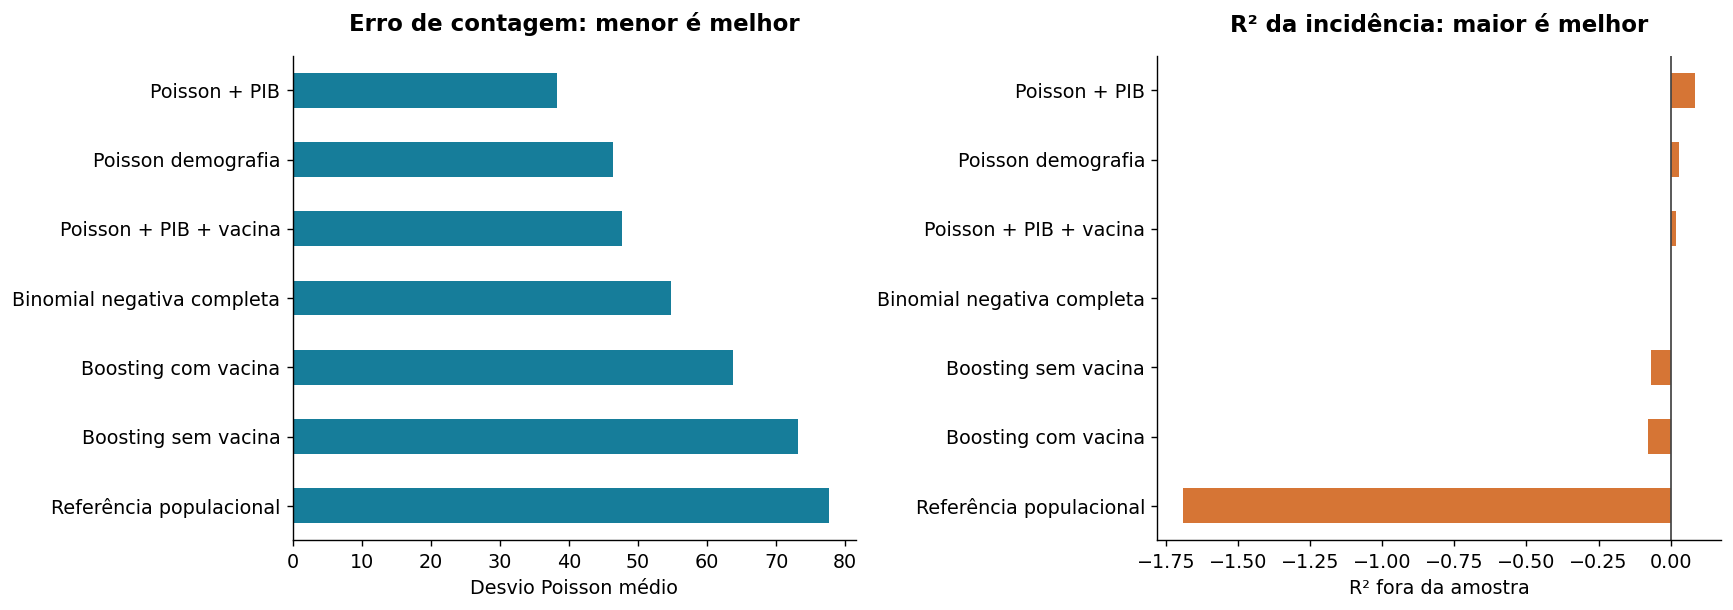

,fold,Pearson_por_gl
0,1,16.47
1,2,14.20
2,3,16.13
3,4,15.13
4,5,4.86


In [19]:
principal=metricas_ml.query("esquema=='espacial'").set_index('modelo').sort_values('desvio_Poisson')
ref=principal.loc['Referência populacional','desvio_Poisson']
principal['melhoria_vs_referencia_%']=100*(1-principal.desvio_Poisson/ref)
display(principal.drop(columns='esquema'))
fig,axs=plt.subplots(1,2,figsize=(14,5))
principal.desvio_Poisson.sort_values(ascending=False).plot.barh(ax=axs[0],color=AZUL)
axs[0].set(title='Erro de contagem: menor é melhor',xlabel='Desvio Poisson médio',ylabel='')
principal.R2_incidencia.sort_values().plot.barh(ax=axs[1],color=LARANJA)
axs[1].axvline(0,color='#444',lw=1);axs[1].set(title='R² da incidência: maior é melhor',xlabel='R² fora da amostra',ylabel='')
plt.tight_layout();plt.show()
print('Dispersão no treino, diagnóstico Poisson (aproximado sob penalização):')
display(dispersao_ml.query("esquema=='espacial'")[['fold','Pearson_por_gl']])

**Resultado principal:** Poisson com demografia e PIB tem o menor desvio espacial observado, cerca de **38,24**, contra **77,70** da referência populacional — redução de aproximadamente **50,8%**. Isso é melhora em relação a uma referência fraca; não significa boa capacidade preditiva absoluta.

Seu **R² de incidência é apenas 0,085**, e a soma das previsões representa aproximadamente **36,7% dos casos observados**. O modelo subestima fortemente o território mais atingido. A binomial negativa e o boosting não superam esse modelo nesse protocolo. A razão de Pearson por grau de liberdade documenta sobre-dispersão residual no treino, mas é um diagnóstico aproximado com regularização, não um teste formal. Permitir sobre-dispersão na distribuição não resolve automaticamente a falta de informação sobre a transmissão.

**Conclusão provisória:** há sinal preditivo além do tamanho da população, mas os indicadores disponíveis não sustentam uma previsão espacial confiável do tamanho da epidemia.

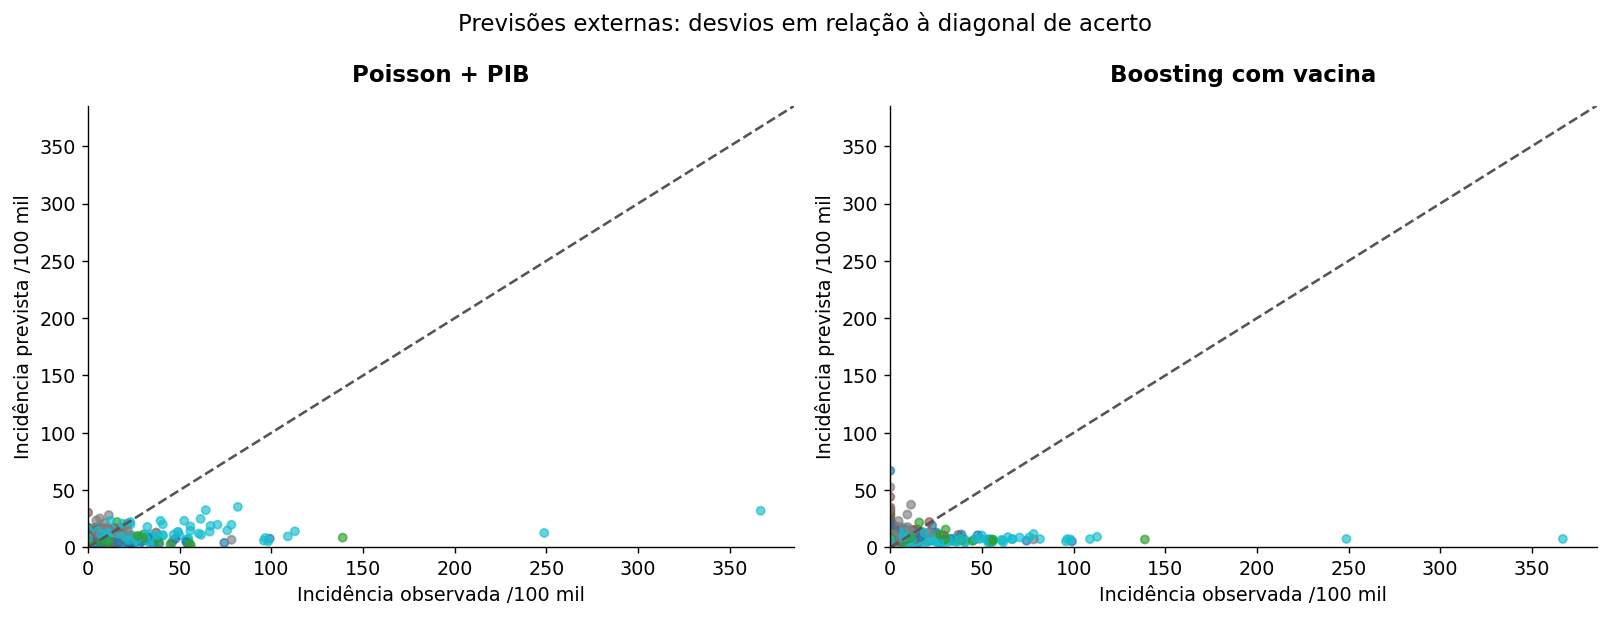

,municipio,casos,populacao,bloco,previsto,erro_absoluto
codigo,,,,,,
355030,São Paulo,9392,12015228,5,"2,365.38","7,026.62"
351880,Guarulhos,889,1339469,5,184.47,704.53
351630,Francisco Morato,621,169229,5,54.09,566.91
351640,Franco da Rocha,365,146664,5,18.50,346.50
354870,São Bernardo do Campo,390,836495,5,92.86,297.14
350570,Barueri,290,302517,5,17.87,272.13
353440,Osasco,365,743089,5,100.21,264.79
352940,Mauá,308,436224,5,86.39,221.61
354780,Santo André,398,759088,5,176.54,221.46


In [20]:
esp=pred_ml.query("esquema=='espacial'").pivot(index='codigo',columns='modelo',values='pred_casos').reindex(base_ml.index)
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,mod in zip(axs,['Poisson + PIB','Boosting com vacina']):
    obs=base_ml.casos/(base_ml.populacao/1e5);prev=esp[mod]/(base_ml.populacao/1e5)
    ax.scatter(obs,prev,c=base_ml.bloco,cmap=plt.get_cmap('tab10',5),vmin=.5,vmax=5.5,alpha=.65,s=22)
    lim=max(obs.max(),prev.max())*1.05;ax.plot([0,lim],[0,lim],'--',color='#555');ax.set_xlim(0,lim);ax.set_ylim(0,lim)
    ax.set(xlabel='Incidência observada /100 mil',ylabel='Incidência prevista /100 mil',title=mod)
plt.suptitle('Previsões externas: desvios em relação à diagonal de acerto');plt.tight_layout();plt.show()
problemas=base_ml[['municipio','casos','populacao','bloco']].copy()
problemas['previsto']=esp['Poisson + PIB'];problemas['erro_absoluto']=(problemas.casos-problemas.previsto).abs()
display(problemas.nlargest(12,'erro_absoluto'))

### 12.5 A vacinação acrescenta capacidade preditiva?

A comparação correta mantém a família do modelo e acrescenta o conjunto vacinal. Comparar o melhor modelo sem vacina a outro algoritmo com vacina confundiria as duas mudanças. A contribuição pode incluir tanto cobertura como qualidade administrativa, pois o conjunto contém o indicador de valores acima de 100%.

,divisao,familia,sem_vacina,com_vacina,melhoria_%
0,espacial,Poisson,38.24,47.64,-24.57
1,espacial,Boosting,73.12,63.82,12.72
2,longitude,Poisson,49.01,48.36,1.32
3,longitude,Boosting,64.16,54.16,15.59
4,aleatorio,Poisson,18.14,20.85,-14.92
5,aleatorio,Boosting,33.85,32.99,2.55


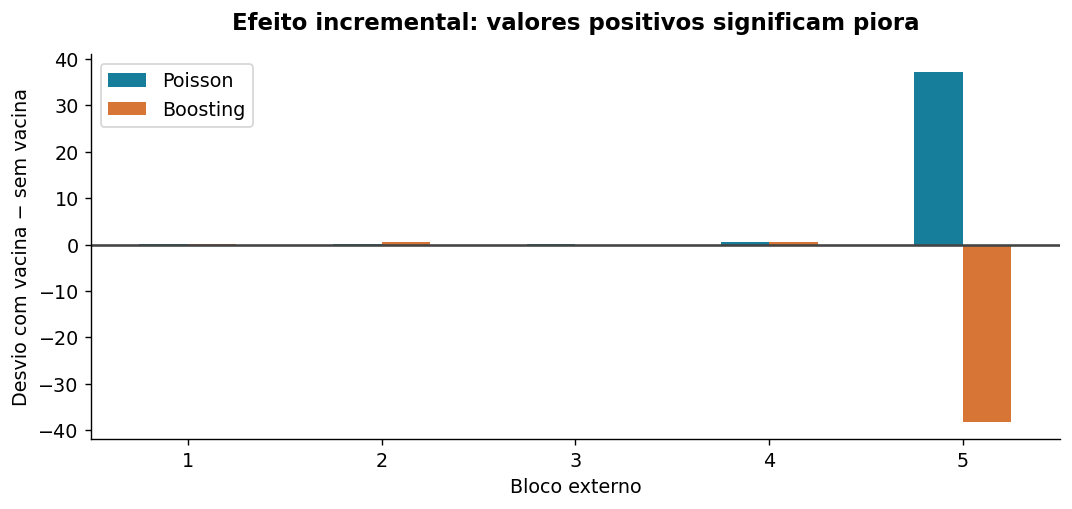

In [21]:
ab=[]
for esq in ['espacial','longitude','aleatorio']:
    sub=metricas_ml.query('esquema==@esq').set_index('modelo')
    for familia,sem,com in [('Poisson','Poisson + PIB','Poisson + PIB + vacina'),('Boosting','Boosting sem vacina','Boosting com vacina')]:
        antes=sub.loc[sem,'desvio_Poisson'];depois=sub.loc[com,'desvio_Poisson']
        ab.append({'divisao':esq,'familia':familia,'sem_vacina':antes,'com_vacina':depois,'melhoria_%':100*(1-depois/antes)})
ablacao=pd.DataFrame(ab);display(ablacao)
f=folds_ml.query("esquema=='espacial'").pivot(index='fold',columns='modelo',values='desvio_Poisson')
delta=pd.DataFrame({'Poisson':f['Poisson + PIB + vacina']-f['Poisson + PIB'],'Boosting':f['Boosting com vacina']-f['Boosting sem vacina']})
delta.plot.bar(color=[AZUL,LARANJA],figsize=(10,4));plt.axhline(0,color='#444');plt.ylabel('Desvio com vacina − sem vacina');plt.xlabel('Bloco externo');plt.title('Efeito incremental: valores positivos significam piora');plt.xticks(rotation=0);plt.show()

No protocolo espacial principal, acrescentar vacinação ao Poisson **piora o desvio em aproximadamente 24,6%** e piora em cada um dos cinco blocos. No boosting, reduz o desvio em cerca de **12,7%**, mas o modelo continua com erro maior que Poisson + PIB e R² negativo.

A contribuição muda com a família e a partição: não há evidência estável de melhora generalizável com esse conjunto vacinal. O resultado se refere a estes indicadores administrativos infantis, neste ano e neste desenho. **Não demonstra ausência de proteção vacinal individual nem ausência de importância epidemiológica da vacinação.** Há descompasso etário, valores administrativos anômalos, confundimento e ausência de medidas de exposição ao vírus.

### 12.6 Robustez à divisão dos dados e às coberturas anômalas

esquema,aleatorio,espacial,longitude
modelo,,,
Binomial negativa completa,13.40,54.72,54.83
Boosting com vacina,32.99,63.82,54.16
Boosting sem vacina,33.85,73.12,64.16
Poisson + PIB,18.14,38.24,49.01
Poisson + PIB + vacina,20.85,47.64,48.36
Poisson demografia,15.47,46.35,48.65
Referência populacional,36.73,77.70,74.84


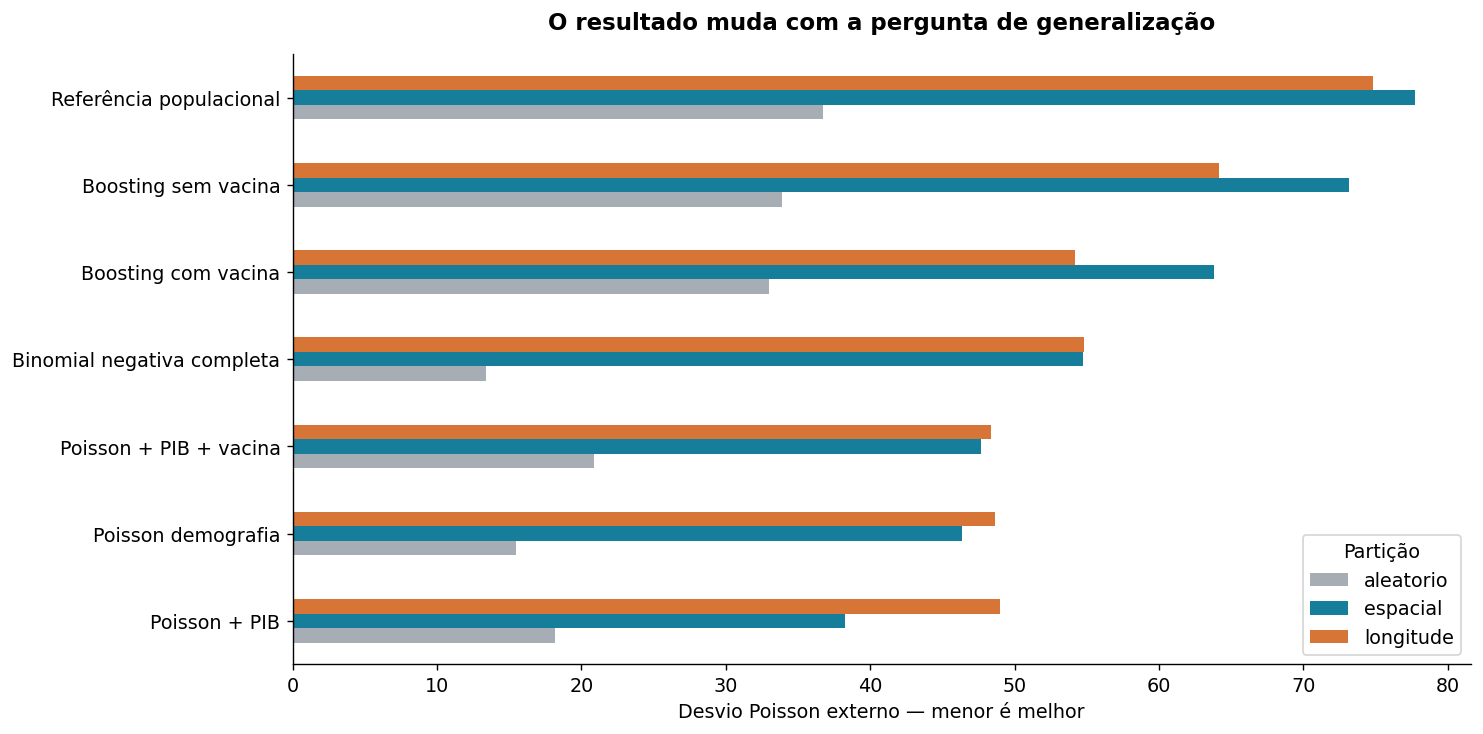

,esquema,modelo,desvio_Poisson,R2_incidencia,razao_pred_obs
8,espacial,Boosting com vacina,63.82,-0.08,0.25
11,espacial,Poisson + PIB + vacina,47.64,0.02,0.31
14,espacial_cob_limitada,Boosting com vacina,67.37,-0.07,0.23
15,espacial_cob_limitada,Poisson + PIB + vacina,48.75,0.01,0.32


,modelo,desvio_Poisson,MAE_incidencia,R2_incidencia,razao_pred_obs
7,Binomial negativa completa,26.59,10.56,0.00,0.38
8,Boosting com vacina,33.40,12.19,-0.08,0.35
9,Boosting sem vacina,29.91,12.23,-0.07,0.37
10,Poisson + PIB,19.90,10.54,0.08,0.49
11,Poisson + PIB + vacina,23.95,10.56,0.02,0.44
12,Poisson demografia,23.14,10.62,0.03,0.44
13,Referência populacional,37.72,33.61,-1.71,0.80


In [22]:
comparacao=metricas_ml[metricas_ml.esquema.isin(['espacial','longitude','aleatorio'])].pivot(index='modelo',columns='esquema',values='desvio_Poisson')
display(comparacao)
comparacao.reindex(principal.index).plot.barh(figsize=(12,6),color=[CINZA,AZUL,LARANJA])
plt.xlabel('Desvio Poisson externo — menor é melhor');plt.ylabel('');plt.title('O resultado muda com a pergunta de generalização');plt.legend(title='Partição');plt.tight_layout();plt.show()
vc=metricas_ml[metricas_ml.esquema.isin(['espacial','espacial_cob_limitada']) & metricas_ml.modelo.isin(['Poisson + PIB + vacina','Boosting com vacina'])]
display(vc[['esquema','modelo','desvio_Poisson','R2_incidencia','razao_pred_obs']])
display(sem_capital_ml.query("esquema=='espacial'")[['modelo','desvio_Poisson','MAE_incidencia','R2_incidencia','razao_pred_obs']])

A divisão aleatória produz resultados melhores: por exemplo, a binomial negativa passa de desvio **54,72** e R² **0,002** na divisão espacial para **13,40** e R² **0,257** na aleatória. Isso não deve ser apresentado como desempenho esperado ao transferir o modelo para uma região não observada.

Na divisão por faixas de longitude, os R² ficam próximos de zero ou negativos. Limitar as coberturas a 100% não resgata o desempenho: o desvio do Poisson completo passa de **47,64 para 48,75** e o do boosting com vacina de **63,82 para 67,37**.

A tabela sem a capital **retira São Paulo somente da avaliação**, mantendo exatamente as previsões externas já calculadas; não é um novo treinamento sem a capital. O Poisson + PIB continua com R² próximo de 0,08 e total previsto aproximadamente 49% do observado nos demais municípios. A dificuldade não é explicada apenas por um único município.

### 12.7 O que os modelos usam e onde falham?

A permutação abaixo embaralha conjuntamente os atributos de um grupo **dentro do bloco de teste**, mantendo a exposição de cada município. Mede quanto o desvio muda, sem refazer o treino. São dez repetições por grupo e bloco. Não é efeito causal, e relações entre grupos podem ser quebradas pelo embaralhamento. Valores negativos indicam que perturbar o grupo melhorou a previsão naquela avaliação.

A importância de uma variável em um modelo de desempenho baixo não demonstra utilidade operacional. As repetições não são amostras independentes de novas epidemias; o desvio padrão mede somente a variabilidade do embaralhamento.

media  ...     maximo
modelo                 grupo                 ...           
Boosting com vacina    Densidade   1.862060  ...  30.851799
                       Idade       0.887397  ...  11.969175
                       PIB        -1.158824  ...   0.970896
                       Vacinação  10.160433  ...  93.556791
Poisson + PIB + vacina Densidade  13.153632  ...  96.597494
                       Idade       1.504424  ...  15.797470
                       PIB        -0.263235  ...  11.277519
                       Vacinação   1.624446  ...  16.583110

[8 rows x 4 columns]

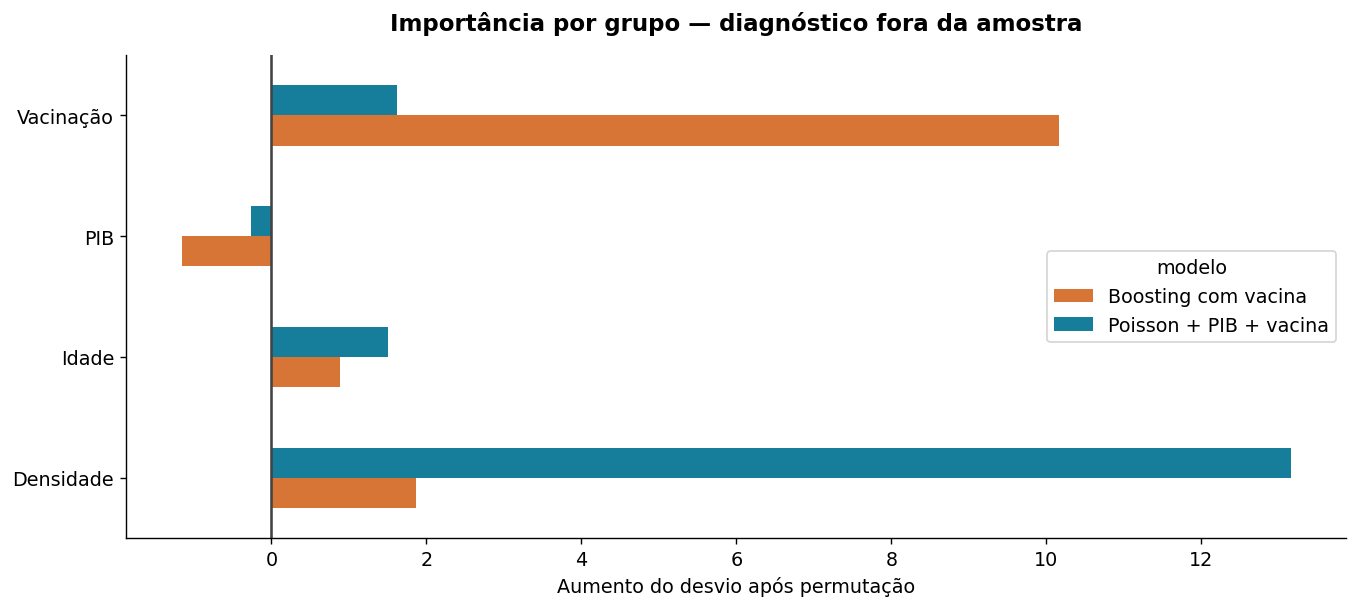

,casos,previsto
bloco,,
1,132,159.79
2,296,211.66
3,261,418.64
4,300,699.40
5,17036,"5,118.92"


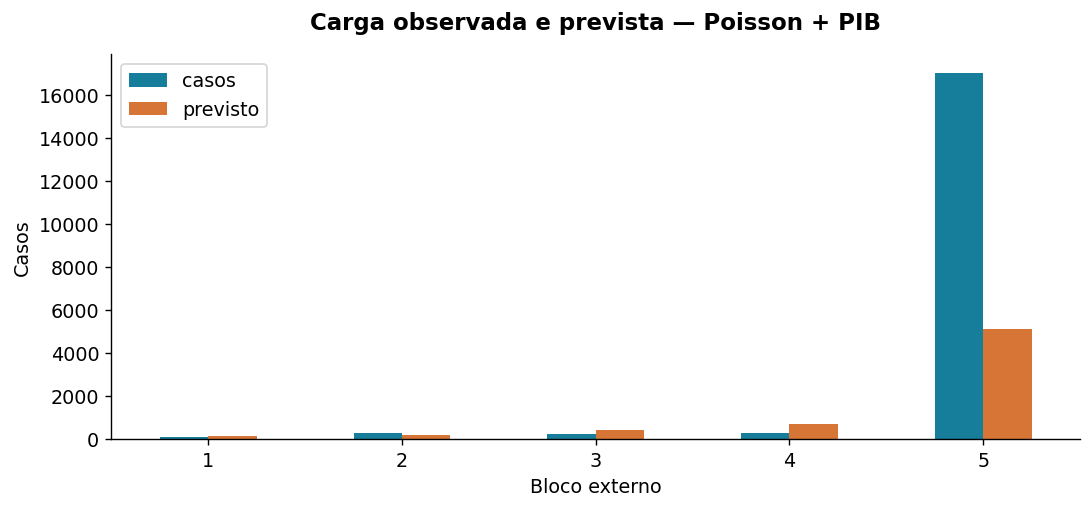

In [23]:
im=perm_ml.groupby(['modelo','grupo']).aumento_desvio.agg(media='mean',desvio_padrao='std',minimo='min',maximo='max')
display(im)
im.media.unstack('modelo').plot.barh(figsize=(11,5),color=[LARANJA,AZUL]);plt.axvline(0,color='#444');plt.xlabel('Aumento do desvio após permutação');plt.title('Importância por grupo — diagnóstico fora da amostra');plt.ylabel('');plt.tight_layout();plt.show()
# Comparação dos totais no bloco, útil para ver a subestimação regional.
balanco=base_ml[['bloco','casos']].copy();balanco['previsto']=esp['Poisson + PIB']
balanco=balanco.groupby('bloco')[['casos','previsto']].sum();display(balanco)
balanco.plot.bar(color=[AZUL,LARANJA],figsize=(10,4));plt.ylabel('Casos');plt.xlabel('Bloco externo');plt.title('Carga observada e prevista — Poisson + PIB');plt.xticks(rotation=0);plt.show()

O modelo aprende associações estruturais, mas não observa a intensidade da exposição ao vírus, a introdução local, mobilidade, contatos ou suscetibilidade detalhada por idade. Esses mecanismos são hipóteses para explicar o erro, não conclusões causais estabelecidas pelos dados. A grande subestimação do bloco mais afetado é evidência de limitação de transferência espacial neste exercício.

Nenhum modelo foi escolhido para uso operacional, nem foram produzidos mapas de risco futuro. As previsões exportadas são previsões retrospectivas fora da amostra, identificadas por divisão, bloco e modelo. Não são probabilidades individuais de adoecer.

### 12.8 Auditoria e conclusão do machine learning

In [24]:
# Cada município aparece uma vez no teste por modelo e divisão.
assert not pred_ml.duplicated(['codigo','esquema','modelo']).any()
assert pred_ml.groupby(['esquema','modelo']).size().eq(645).all()
assert np.isfinite(pred_ml.pred_casos).all() and pred_ml.pred_casos.gt(0).all()
assert base_ml.casos.sum()==18025 and len(base_ml)==645
# Recalcular as métricas a partir das previsões exportadas.
recalculadas=modelagem.resumir(base_ml,pred_ml).sort_values(['esquema','modelo']).reset_index(drop=True)
registradas=metricas_ml.sort_values(['esquema','modelo']).reset_index(drop=True)
for c in ['desvio_Poisson','MAE_casos','MAE_incidencia','R2_incidencia','razao_pred_obs']:
    assert np.allclose(recalculadas[c],registradas[c],rtol=1e-8,atol=1e-8)
print('Auditoria ML concluída: cobertura dos testes, unicidade, previsões positivas, hashes e métricas reconciliados.')
display(folds_ml.query("esquema=='espacial'")[['fold','modelo','hiper','n_treino','n_teste']])

Auditoria ML concluída: cobertura dos testes, unicidade, previsões positivas, hashes e métricas reconciliados.


,fold,modelo,hiper,n_treino,n_teste
0,1,Referência populacional,0.00,530,115
1,1,Poisson demografia,1.00,530,115
2,1,Poisson + PIB,1.00,530,115
3,1,Poisson + PIB + vacina,0.10,530,115
4,1,Binomial negativa completa,1.00,530,115
5,1,Boosting sem vacina,3.00,530,115
6,1,Boosting com vacina,3.00,530,115
7,2,Referência populacional,0.00,528,117
8,2,Poisson demografia,0.10,528,117
9,2,Poisson + PIB,0.10,528,117


**O estudo produziu um resultado útil, mesmo sem um modelo suficientemente bom:**

1. Há alguma capacidade preditiva além da população: demografia e PIB reduzem o desvio relativo à referência.
2. A generalização para uma região inteira é fraca. O melhor R² espacial observado é apenas 0,085 e há forte subestimação da carga.
3. A vacinação administrativa não traz ganho consistente entre famílias de modelos e divisões. Seu valor preditivo neste conjunto não se confunde com proteção vacinal individual.
4. Modelos mais complexos não resolveram a limitação. A binomial negativa ajuda a representar sobre-dispersão, mas informação ausente sobre transmissão e mudança de distribuição permanecem.
5. O contraste espacial versus aleatório é um achado metodológico: um bom resultado aleatório poderia dar confiança excessiva para aplicação em outra região.

**Próximos dados com maior potencial:** múltiplos anos e epidemias para teste temporal; mobilidade e conectividade; datas e localização de introduções; cobertura e suscetibilidade por idade; medidas comparáveis de vigilância. A próxima etapa deve melhorar a informação e a validação antes de ampliar a busca por algoritmos.

**Arquivos reproduzíveis:** `scripts/modelagem.py` contém a preparação de atributos, os modelos e todas as partições; `results/ml` contém base analítica, previsões, métricas, ajustes internos, diagnósticos e hashes. Para reconstruir: `python scripts/modelagem.py` ou defina `RECALCULAR_ML=True` na seção 12.2 e execute. Nenhuma fonte externa é necessária depois da instalação das dependências.

A seleção e os testes documentados permitem defender uma conclusão moderada: **estes indicadores conseguem descrever parte da heterogeneidade municipal, mas são insuficientes para prever de forma confiável a concentração espacial da epidemia de 2019.**

## 13. Perfis municipais: gráfico simples e clustering exploratório

**Pergunta:** é possível resumir os municípios em perfis que combinem cobertura vacinal declarada, intensidade da epidemia e contexto demográfico? O objetivo é verificar se o agrupamento acrescenta uma descrição útil, mesmo que os grupos sejam imperfeitos.

Esta etapa é **não supervisionada** e retrospectiva. A incidência de 2019 participa da definição dos grupos; encontrar diferenças de incidência entre eles é esperado por construção e **não é validação independente**. Não estamos prevendo casos futuros nem demonstrando causas.

Estes grupos de perfil também não são os cinco blocos geográficos da seção 12: aqueles servem para separar treino e teste; aqui as coordenadas não entram no agrupamento. “Cobertura elevada” significa valor administrativo registrado, não imunidade comprovada da população. Os indicadores são infantis, enquanto os casos incluem todas as idades.

In [25]:
import clustering
importlib.reload(clustering)
CL = ROOT / 'results' / 'clustering'
RECALCULAR_CLUSTERING = False
valid_cl=False
if (CL/'execucao.json').exists():
    info_cl=json.loads((CL/'execucao.json').read_text(encoding='utf-8'))
    valid_cl=info_cl['assinatura']==clustering.assinatura()
    valid_cl=valid_cl and all((CL/arq).exists() and hashlib.sha256((CL/arq).read_bytes()).hexdigest()==sha for arq,sha in info_cl['arquivos'].items())
if RECALCULAR_CLUSTERING or not valid_cl:
    clustering.run(CL)
info_cl=json.loads((CL/'execucao.json').read_text(encoding='utf-8'))
cl=pd.read_csv(CL/'municipios.csv',dtype={'codigo':str}).set_index('codigo')
perfis_cl=pd.read_csv(CL/'perfis.csv',index_col='grupo')
selecao_cl=pd.read_csv(CL/'selecao_k.csv')
estab_cl=pd.read_csv(CL/'estabilidade.csv')
jacc_cl=pd.read_csv(CL/'jaccard.csv')
sens_cl=pd.read_csv(CL/'sensibilidades.csv')
controle_cl=pd.read_csv(CL/'controle_permutado.csv')
centros_cl=pd.read_csv(CL/'centros_padronizados.csv',index_col='grupo')
casos_cl=pd.read_csv(CL/'perfil_casos.csv',index_col='grupo')
K=info_cl['k']; cores_cl=['#a66c23','#287d8e','#a93f62','#6654a6','#5e8b3a','#777777']
print('Municípios:',len(cl),'| k selecionado:',K,'| silhueta:',round(info_cl['silhueta'],3))

Municípios: 645 | k selecionado: 3 | silhueta: 0.323


### 13.1 Primeiro: quatro situações em um gráfico simples

Eixo horizontal: média municipal de D2 em 2016–2018, **sem truncar os valores originais**. Eixo vertical: incidência de 2019. As linhas são a mediana municipal da cobertura (**87,04%**) e a incidência estadual (**39,78 por 100 mil**).

São referências descritivas escolhidas para organizar o gráfico, **não metas vacinais nem limiares clínicos**. “Incidência menor” inclui zero e valores positivos abaixo da referência; não significa necessariamente “não atingido”. A tabela apresenta separadamente os municípios sem casos. Os quadrantes mudariam com outros limiares, enquanto o gráfico contínuo preserva a informação.

As situações “cobertura maior/incidência maior” e “cobertura menor/incidência menor” não são paradoxos comprovados: podem refletir exposição ao vírus, descompasso etário, registros administrativos, vigilância ou acaso. Esses mecanismos não são identificados causalmente pelo gráfico.

,municipios,sem_casos,casos,populacao,D2_mediana,incidencia_mediana,incidencia_agregada
quadrante,,,,,,,
Cobertura maior / incidência maior,12,0,466,677399,100.88,55.32,68.79
Cobertura maior / incidência menor,311,199,1361,10675890,100.41,0.00,12.75
Cobertura menor / incidência maior,30,0,14625,19356696,75.56,60.90,75.56
Cobertura menor / incidência menor,292,139,1573,14596154,73.63,2.20,10.78


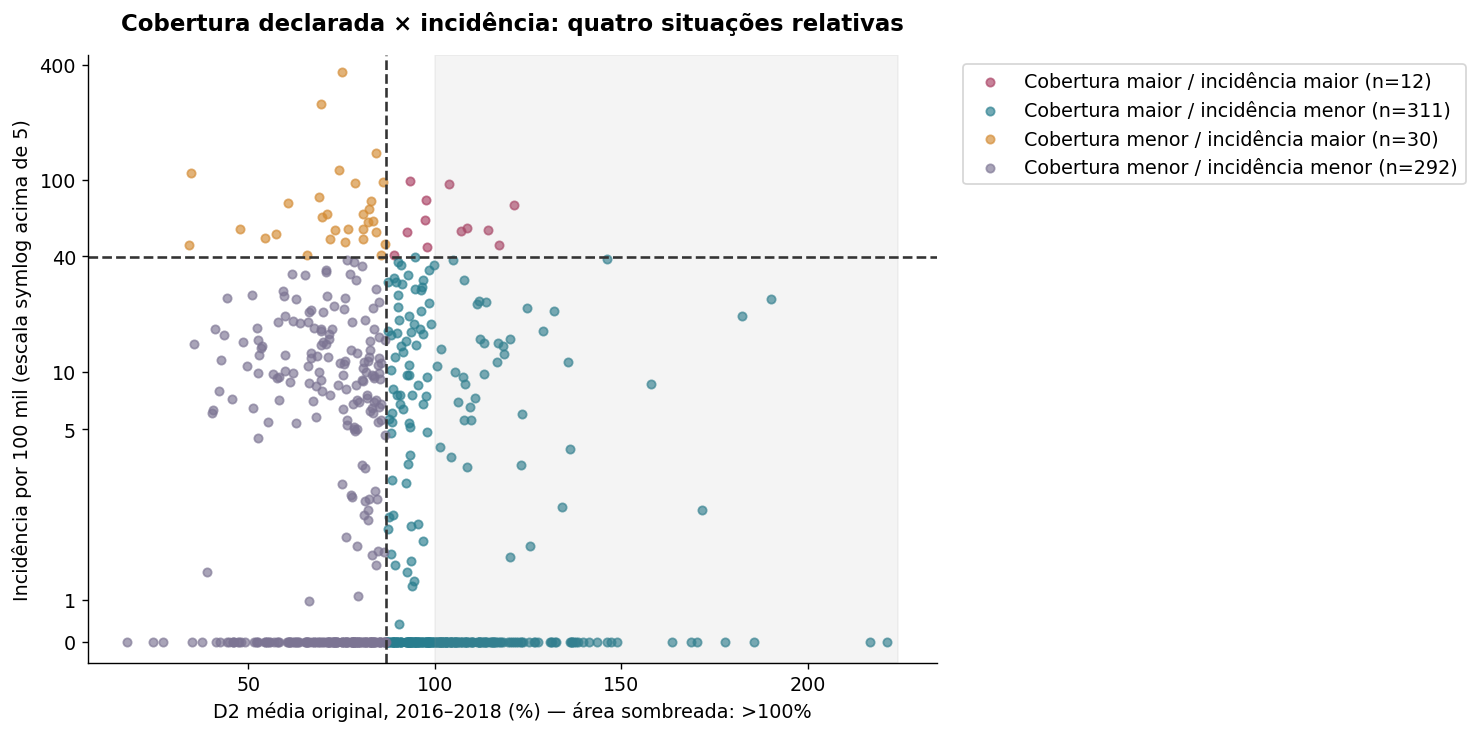

In [26]:
quad=cl.groupby('quadrante').agg(municipios=('casos','size'),sem_casos=('casos',lambda x:(x==0).sum()),casos=('casos','sum'),populacao=('populacao','sum'),D2_mediana=('d2_media_original','median'),incidencia_mediana=('incidencia','median'))
quad['incidencia_agregada']=quad.casos/quad.populacao*1e5
display(quad)
fig,ax=plt.subplots(figsize=(12,6))
for cor,(nome,g) in zip(['#a93f62','#287d8e','#d38a32','#7c7493'],cl.groupby('quadrante')):
    ax.scatter(g.d2_media_original,g.incidencia,label=f'{nome} (n={len(g)})',s=23,alpha=.65,color=cor)
ax.axvline(info_cl['limiar_D2'],color='#333',ls='--');ax.axhline(info_cl['limiar_incidencia'],color='#333',ls='--')
ax.axvspan(100,max(105,cl.d2_media_original.max()+3),color='#999',alpha=.1)
ax.set_yscale('symlog',linthresh=5);ax.set_ylim(-.5,450)
ax.set_yticks([0,1,5,10,40,100,400],labels=['0','1','5','10','40','100','400'])
ax.set(xlabel='D2 média original, 2016–2018 (%) — área sombreada: >100%',ylabel='Incidência por 100 mil (escala symlog acima de 5)',title='Cobertura declarada × incidência: quatro situações relativas')
ax.legend(loc='upper left',bbox_to_anchor=(1.02,1));plt.tight_layout();plt.show()

### 13.2 O que acrescentamos no clustering

Sete variáveis, reunidas em três dimensões:

| Dimensão | Variáveis | Peso na distância |
|---|---|---|
| Vacinação | Médias D1/D2 e diferenças 2018−2016 | Cada variável padronizada × 1/√4 |
| Intensidade | `log(1 + incidência)` | Variável padronizada × 1 |
| Demografia | Log da densidade e proporção de crianças de 0–4 anos | Cada variável padronizada × 1/√2 |

A padronização retira a diferença de unidades. A ponderação equaliza a contribuição nominal dos três blocos para a distância quadrática; não elimina correlações dentro deles. A população não pesa as observações: cada município vale uma observação. PIB, número absoluto de casos, faixa etária dos casos e hospitalizações são usados **somente depois**, para descrever os perfis.

Na análise principal, cada cobertura anual >100% é limitada a 100% **antes** das médias e diferenças. Isso reduz a influência dos extremos, mas não os corrige comprovadamente; resultados sem essa transformação e com outros tratamentos são mostrados adiante. Nenhum município é excluído na solução principal.

Ajustamos k-means para **k=2 a 6**, com 30 inicializações e semente 42. Escolhemos a maior silhueta entre soluções com pelo menos 20 municípios em cada grupo. O limite de tamanho é uma regra prática explícita, não uma propriedade epidemiológica. Não impomos quatro grupos para reproduzir os quatro quadrantes.

[Documentação de clustering, silhueta e ARI — scikit-learn](https://scikit-learn.org/stable/modules/clustering.html). A silhueta compara distâncias dentro e entre grupos: valores próximos de zero indicam sobreposição; valor alto não comprova categorias naturais. Não existe um limiar universal que torne os grupos “verdadeiros”.

Diferença silhueta k=3 − k=2: 0.0018690037106813828


,k,silhueta,menor_grupo,maior_grupo
0,2,0.32,283,362
1,3,0.32,63,317
2,4,0.28,59,308
3,5,0.22,55,205
4,6,0.22,54,170


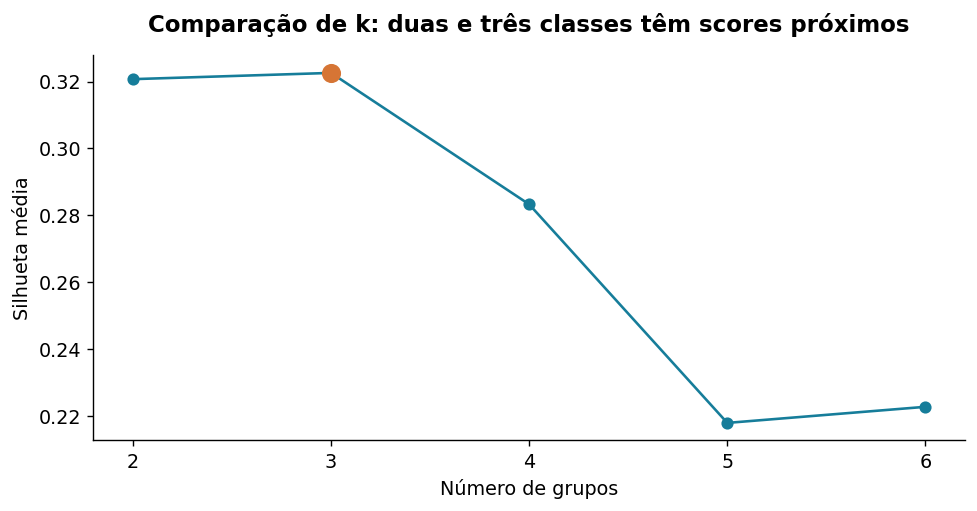

In [27]:
display(selecao_cl)
fig,ax=plt.subplots(figsize=(9,4));ax.plot(selecao_cl.k,selecao_cl.silhueta,marker='o',color=AZUL)
ax.scatter([K],[info_cl['silhueta']],s=100,color=LARANJA,zorder=3)
ax.set(xticks=range(2,7),xlabel='Número de grupos',ylabel='Silhueta média',title='Comparação de k: duas e três classes têm scores próximos');plt.show()
print('Diferença silhueta k=3 − k=2:',float(selecao_cl.set_index('k').loc[3,'silhueta']-selecao_cl.set_index('k').loc[2,'silhueta']))

O critério seleciona **três grupos**, com silhueta **0,323**. Porém, k=2 apresenta **0,321**: a diferença de apenas **0,0019** não sustenta afirmar que existem exatamente três classes. A solução de três grupos é apresentada porque permite descrever um perfil vacinal adicional, mantendo a solução de dois grupos como alternativa exportada.

A separação é parcial: a silhueta sugere sobreposição, e o k-means sempre encontra uma partição mesmo quando os dados formam um contínuo. Precisamos examinar perfis, estabilidade e sensibilidade antes de atribuir significado aos rótulos.

### 13.3 Perfis encontrados

Os IDs foram ordenados pela incidência mediana somente para facilitar a leitura; não representam ordem de qualidade ou prioridade sanitária. Os nomes abaixo são descrições posteriores, não classes impostas ao algoritmo.

- **Grupo 1 — cobertura registrada menor, aumento registrado e poucos casos:** 63 municípios. Médias vacinais mais baixas, mas grandes aumentos entre 2016 e 2018. Isso pode ser mudança real ou de registro; não comprova campanha bem-sucedida.
- **Grupo 2 — cobertura registrada maior e incidência muito baixa:** 317 municípios, em geral menos densos. Os valores administrativos >100% são frequentes nas fontes; o perfil depende parcialmente do tratamento adotado.
- **Grupo 3 — maior densidade e maior carga registrada:** 265 municípios. Concentra 17.934 casos, mas reúne municípios de incidências muito diferentes. Não significa que todos sejam pouco vacinados ou tenham alto risco futuro.

A incidência agregada usa a soma dos casos dividida pela soma das populações. A mediana municipal responde a outra pergunta e pode ser zero mesmo que o grupo tenha casos.

,n,casos,incidencia_mediana,incidencia_agregada,d1_mediana,d2_mediana,d1_delta_mediana,d2_delta_mediana,densidade_mediana,pib_pc_mediano,criancas_mediana_%
grupo,,,,,,,,,,,
1,63,53,0.00,4.66,69.39,55.56,45.19,41.79,25.31,"23,646.00",6.59
2,317,38,0.00,0.76,95.37,89.61,0.00,0.00,27.94,"22,289.14",6.62
3,265,17934,13.53,45.81,92.23,82.51,0.00,-1.52,127.45,"27,774.28",6.81


casos,Com casos,Sem casos
grupo,,
1,17,46
2,25,292
3,265,0


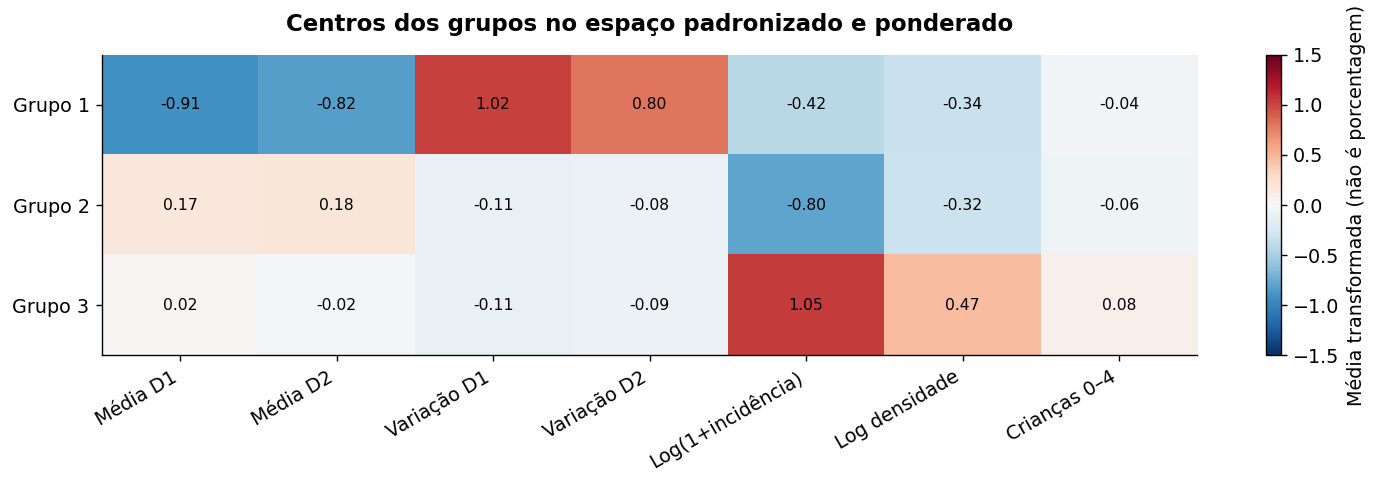

In [28]:
mostrar=perfis_cl[['n','casos','incidencia_mediana','incidencia_agregada','d1_mediana','d2_mediana','d1_delta_mediana','d2_delta_mediana','densidade_mediana','criancas_mediana','pib_pc_mediano']].copy()
mostrar['criancas_mediana_%']=mostrar.pop('criancas_mediana')*100
display(mostrar)
display(pd.crosstab(cl.grupo,cl.casos.eq(0)).rename(columns={False:'Com casos',True:'Sem casos'}))
fig,ax=plt.subplots(figsize=(12,4));im=ax.imshow(centros_cl.to_numpy(),cmap='RdBu_r',aspect='auto',vmin=-1.5,vmax=1.5)
ax.set_xticks(range(len(centros_cl.columns)),['Média D1','Média D2','Variação D1','Variação D2','Log(1+incidência)','Log densidade','Crianças 0–4'],rotation=30,ha='right')
ax.set_yticks(range(K),[f'Grupo {x}' for x in centros_cl.index]);ax.set_title('Centros dos grupos no espaço padronizado e ponderado')
for i in range(K):
    for j in range(len(centros_cl.columns)):ax.text(j,i,f'{centros_cl.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9)
fig.colorbar(im,ax=ax,label='Média transformada (não é porcentagem)');plt.tight_layout();plt.show()

O grupo 2 tem **292 municípios sem casos**; o grupo 1, **46**; o grupo 3 tem casos em todos os seus municípios. Esse contraste é, em parte, consequência de incluir incidência no agrupamento. Não deve ser apresentado como descoberta preditiva.

O grupo 1 acrescenta uma distinção de trajetória vacinal: não basta saber apenas se o município teve poucos casos. Entretanto, seu aumento mediano de cobertura é administrativo e pode depender de valores baixos no início da série. A hipótese de melhora real precisa ser confirmada com doses, denominadores e histórico local.

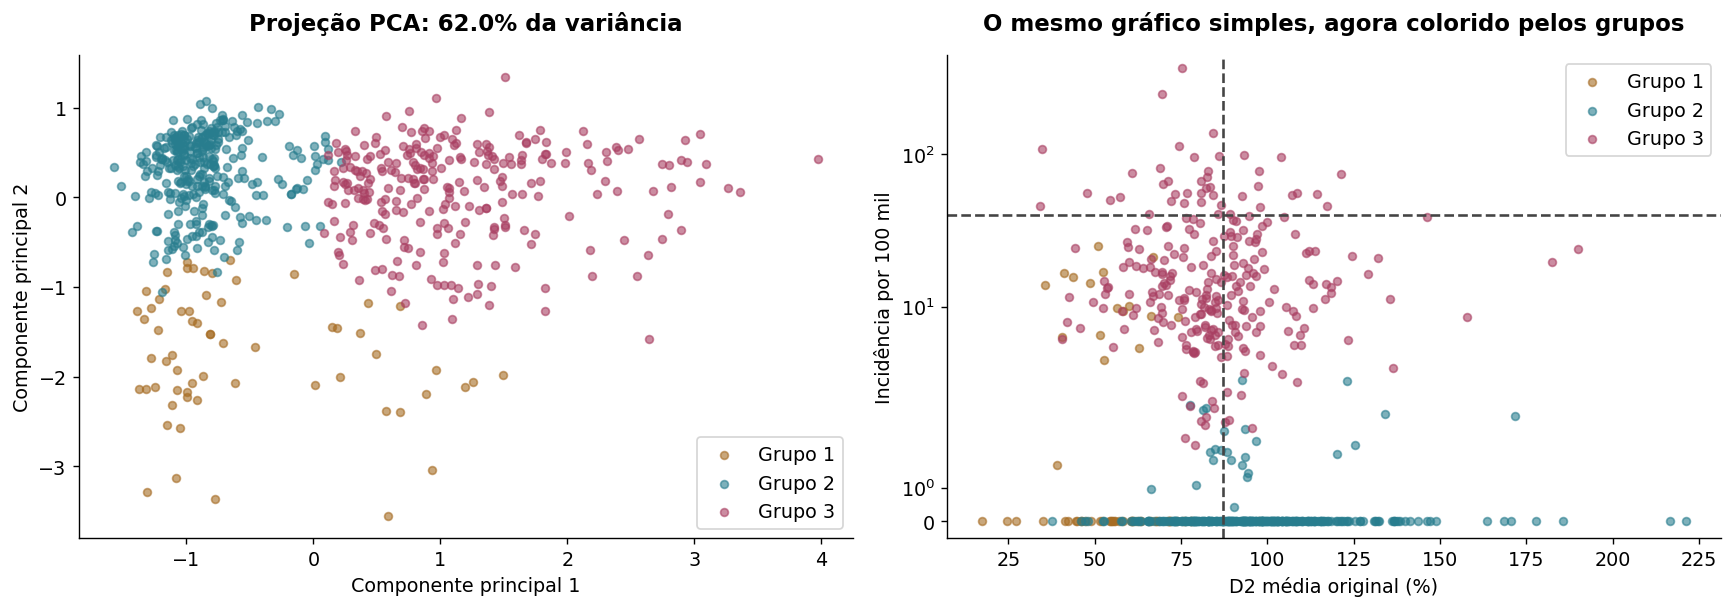

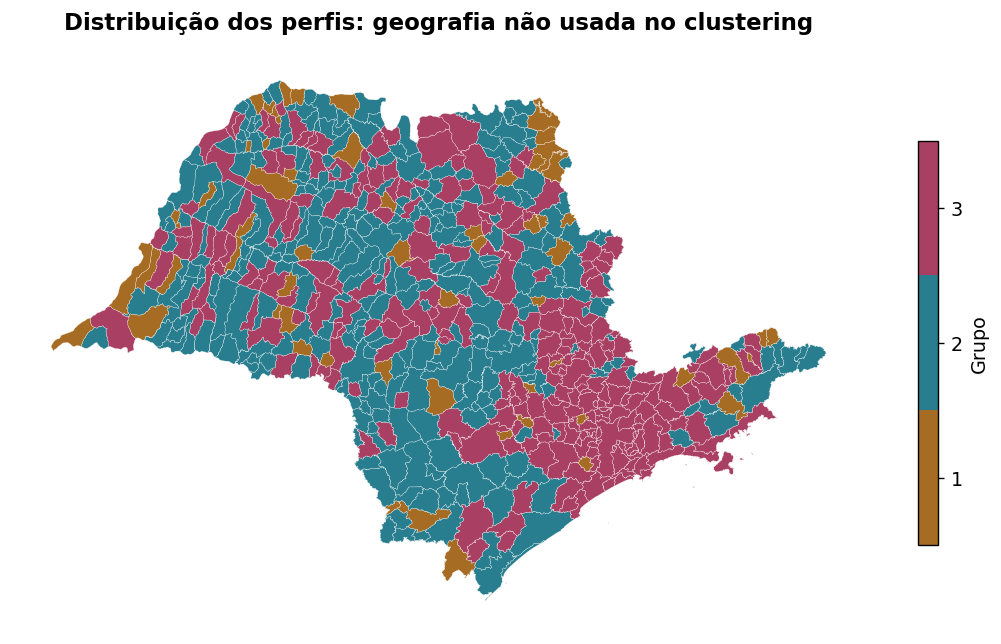

In [29]:
fig,axs=plt.subplots(1,2,figsize=(14,5))
for g in range(1,K+1):
    s=cl[cl.grupo==g]
    axs[0].scatter(s.PC1,s.PC2,color=cores_cl[g-1],s=20,alpha=.6,label=f'Grupo {g}')
    axs[1].scatter(s.d2_media_original,s.incidencia,color=cores_cl[g-1],s=20,alpha=.6,label=f'Grupo {g}')
axs[0].set(xlabel='Componente principal 1',ylabel='Componente principal 2',title=f'Projeção PCA: {sum(info_cl["PCA_variancia"])*100:.1f}% da variância')
axs[1].axvline(info_cl['limiar_D2'],color='#444',ls='--');axs[1].axhline(info_cl['limiar_incidencia'],color='#444',ls='--')
axs[1].set_yscale('symlog',linthresh=5);axs[1].set_ylim(-.5,450)
axs[1].set(xlabel='D2 média original (%)',ylabel='Incidência por 100 mil',title='O mesmo gráfico simples, agora colorido pelos grupos')
axs[0].legend();axs[1].legend();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(11,6));pol=[];values=[]
for cod,partes in malha.items():
    for parte in partes:pol.append(np.asarray(parte));values.append(cl.loc[cod,'grupo'])
pc=PolyCollection(pol,array=np.asarray(values),cmap=ListedColormap(cores_cl[:K]),clim=(.5,K+.5),edgecolors='white',linewidths=.15)
ax.add_collection(pc);ax.autoscale_view();ax.set_aspect(1/np.cos(np.deg2rad(23)));ax.set_axis_off();ax.set_title('Distribuição dos perfis: geografia não usada no clustering')
fig.colorbar(pc,ax=ax,ticks=range(1,K+1),shrink=.7,label='Grupo');plt.show()

A PCA é apenas uma projeção visual dos sete atributos transformados: o clustering foi feito no espaço completo. Os dois eixos preservam aproximadamente **62%** da variância; separação ou sobreposição na figura não resume toda a geometria. O mapa mostra onde os perfis ocorrem, sem permitir inferir transmissão entre municípios.

### 13.4 Descrição adicional, fora das variáveis do clustering

Faixa etária dos casos, calendário e hospitalização não foram usados para formar os grupos. A tabela abaixo ajuda a caracterizá-los, mas não é validação externa: vem da mesma epidemia. Nos grupos com apenas 38 ou 53 casos, porcentagens variam muito com poucos registros. Hospitalizações usam somente fichas com informação conhecida; as contagens do denominador são mostradas.

In [30]:
display(casos_cl)
print('PIB por habitante (mediana municipal), variável não usada para agrupar:')
display(perfis_cl[['pib_pc_mediano']])

PIB por habitante (mediana municipal), variável não usada para agrupar:


,casos,adultos20a29,julho_setembro,hospitalizados,hospitalizacao_conhecida,adultos20a29_%,julho_setembro_%,hospitalizados_%_conhecidos
grupo,,,,,,,,
1,53,10,44,7,51,18.87,83.02,13.73
2,38,4,27,10,37,10.53,71.05,27.03
3,17934,5577,12986,2232,16218,31.10,72.41,13.76


,pib_pc_mediano
grupo,
1,"23,646.00"
2,"22,289.14"
3,"27,774.28"


### 13.5 Estabilidade: reaparece quando os dados mudam um pouco?

Realizamos **40 subamostragens sem reposição de 80% dos municípios**. Em cada uma, recalculamos medianas de imputação, padronização e k-means. Para avaliar estabilidade com k fixo, projetamos todos os 645 municípios no modelo ajustado na subamostra e comparamos a partição à original.

O **ARI** compara partições independentemente dos números dos rótulos: 1 indica coincidência, valores próximos de zero correspondem ao nível esperado sob seu ajuste por acaso. O **Jaccard** mede a sobreposição de cada grupo após correspondência ótima dos rótulos. A concordância de cada município é a fração das 40 repetições em que manteve seu grupo após essa correspondência.

Isso mede estabilidade à retirada de observações, **não desempenho em dados futuros**; 80% dos municípios usados na comparação também participaram de cada ajuste. Separadamente, voltamos a escolher k entre 2 e 6 em cada subamostra. Assim distinguimos estabilidade da partição com k fixo e incerteza sobre quantos grupos usar.

Frequência de k escolhido nas 40 subamostras:


,ARI
count,40.00
mean,0.98
std,0.01
min,0.95
5%,0.97
50%,0.98
95%,1.00
max,1.00


,mean,min,max
grupo,,,
1,0.96,0.84,1.00
2,0.99,0.97,1.00
3,0.99,0.97,1.00


,repetições
k_reselecionado,
2,4
3,36


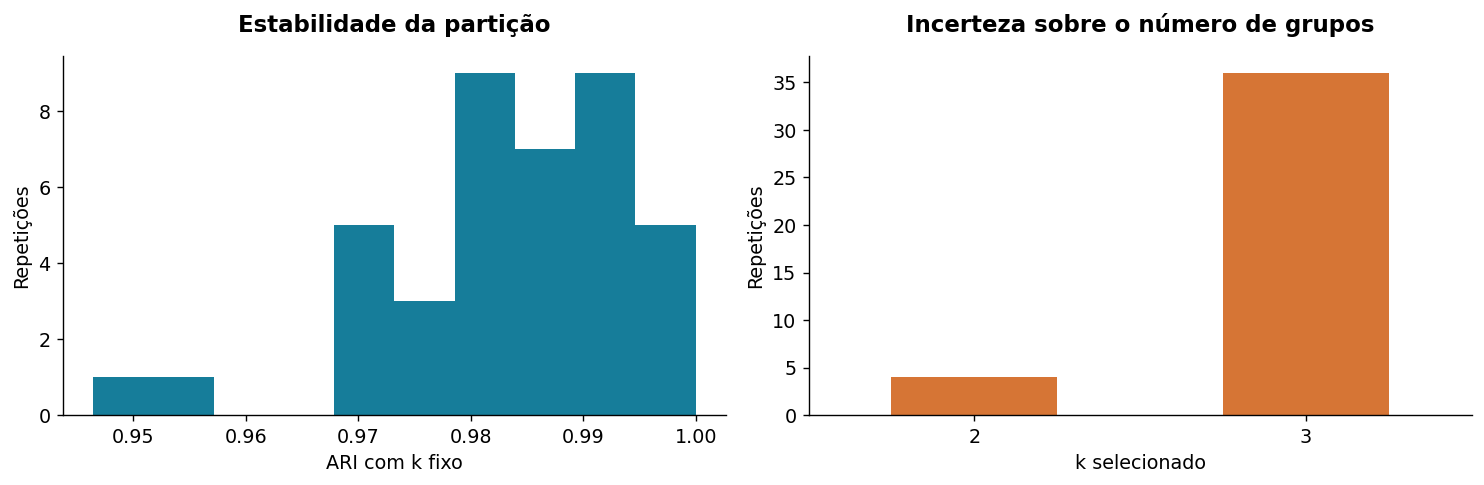

,municipio,grupo,concordancia_reamostragem,d2_media_original,incidencia
codigo,,,,,
355340,Tanabi,1,0.35,76.09,0.00
350540,Barra do Turvo,1,0.50,24.62,0.00
353140,Monte Aprazível,3,0.62,93.28,4.39
355380,Taquarituba,3,0.70,108.61,4.11
353870,Piracicaba,2,0.72,93.66,1.91
354085,Pracinha,2,0.82,75.21,0.00
354530,Salto de Pirapora,3,0.82,79.06,2.25
352265,Itapirapuã Paulista,2,0.85,88.68,0.00
352930,Matão,3,0.85,76.28,2.46


In [31]:
display(estab_cl[['ARI']].describe(percentiles=[.05,.5,.95]))
display(jacc_cl.groupby('grupo').Jaccard.agg(['mean','min','max']))
print('Frequência de k escolhido nas 40 subamostras:');display(estab_cl.k_reselecionado.value_counts().sort_index().to_frame('repetições'))
fig,axs=plt.subplots(1,2,figsize=(12,4));axs[0].hist(estab_cl.ARI,bins=10,color=AZUL);axs[0].set(xlabel='ARI com k fixo',ylabel='Repetições',title='Estabilidade da partição')
estab_cl.k_reselecionado.value_counts().sort_index().plot.bar(ax=axs[1],color=LARANJA);axs[1].set(title='Incerteza sobre o número de grupos',xlabel='k selecionado',ylabel='Repetições');axs[1].tick_params(axis='x',rotation=0);plt.tight_layout();plt.show()
display(cl.nsmallest(10,'concordancia_reamostragem')[['municipio','grupo','concordancia_reamostragem','d2_media_original','incidencia']])

Com três grupos fixos, a estabilidade é alta: **ARI médio ≈0,983**, mínimo ≈0,946. Ao reescolher k em cada subamostra, três grupos são escolhidos em 36 das 40 repetições e dois grupos em quatro. Há, porém, municípios de fronteira que mudam de grupo. Uma boa estabilidade com k fixo não elimina a quase igualdade dos scores de duas e três classes, nem a sensibilidade às escolhas de preparação.

### 13.6 Sensibilidade: os grupos dependem das nossas escolhas?

Mantemos k=3 para comparar partições. Avaliamos coberturas originais; valores >100% tratados como ausentes e imputados pela mediana; exclusão de municípios que tenham qualquer valor >100%; retirada da incidência; e agrupamento hierárquico de Ward no mesmo espaço ponderado. No cenário de exclusão, o ARI compara somente os municípios restantes, portanto muda também a população analisada.

Médias vacinais com ausências usam os anos válidos disponíveis; diferenças precisam dos dois anos extremos. O que continuar ausente é imputado. Isso é uma hipótese alternativa, não identificação do valor verdadeiro. Silhuetas em espaços ou subconjuntos diferentes não são diretamente comparáveis para declarar uma preparação vencedora.

Controle com colunas embaralhadas separadamente:
Silhueta observada: 0.3225811509267585


,cenario,n,ARI_vs_principal,silhueta_no_espaco_proprio
0,Coberturas originais,645,0.57,0.23
1,>100 como ausente,645,0.93,0.32
2,Sem valores >100,160,0.41,0.23
3,Sem incidência,645,0.33,0.27
4,Ward,645,0.78,0.30
5,Só incidência,645,0.59,NaN
6,Só densidade,645,0.14,NaN
7,Só D2,645,0.11,NaN


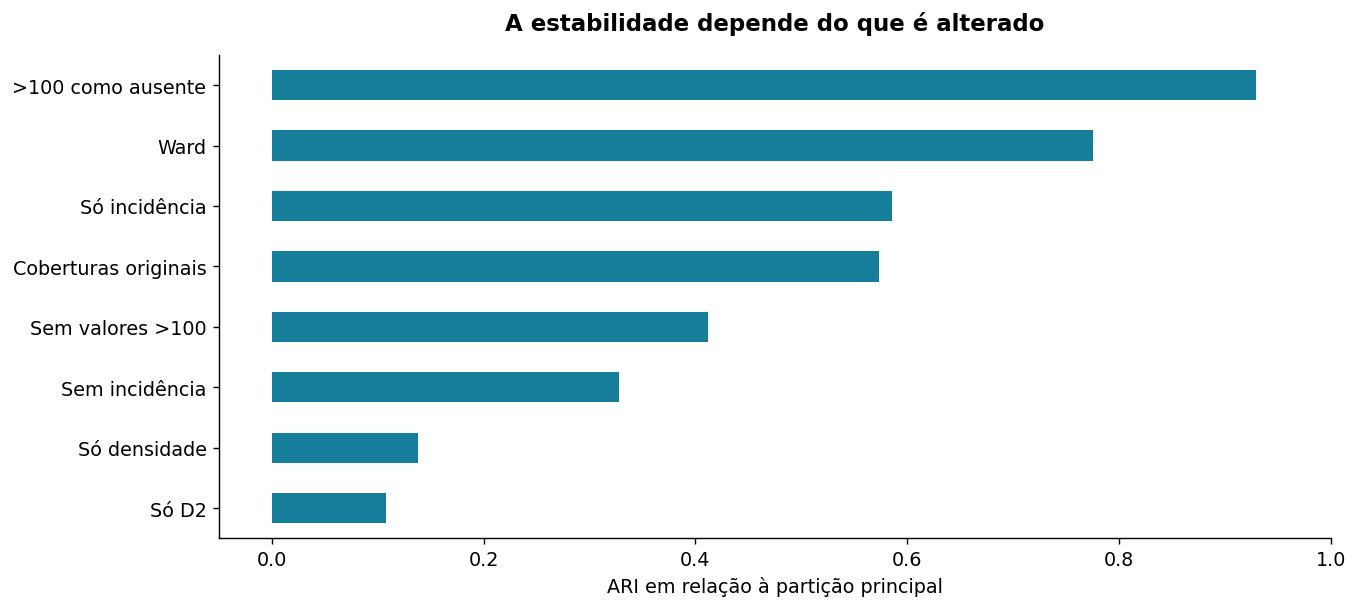

,Melhor silhueta entre k=2 e 6
count,20.00
mean,0.27
std,0.00
min,0.27
25%,0.27
50%,0.27
75%,0.28
max,0.28


In [32]:
display(sens_cl)
sens_cl.set_index('cenario').ARI_vs_principal.sort_values().plot.barh(color=AZUL,figsize=(11,5))
plt.xlim(-.05,1);plt.xlabel('ARI em relação à partição principal');plt.ylabel('');plt.title('A estabilidade depende do que é alterado');plt.tight_layout();plt.show()
print('Controle com colunas embaralhadas separadamente:')
display(controle_cl.melhor_silhueta.describe().to_frame('Melhor silhueta entre k=2 e 6'))
print('Silhueta observada:',info_cl['silhueta'])

A concordância com a solução principal é **0,573 usando coberturas originais**, **0,929 tratando >100% como ausente**, e **0,776 usando Ward**. Excluir municípios com qualquer cobertura >100% deixa apenas **160 municípios**, com ARI **0,412** nesse subconjunto; não representa mais todo o estado.

Retirar a incidência reduz o ARI para **0,328**. Agrupar só pela incidência produz ARI **0,586**; só pela densidade, **0,138**; só por D2, **0,108**. Portanto, a partição tem forte componente de intensidade epidêmica, mas não é idêntica a um agrupamento univariado. Esses números não demonstram que a complexidade adicional seja necessária para toda finalidade.

Como controle exploratório, embaralhamos cada atributo separadamente em 20 repetições, preservando marginais e refazendo a escolha de k. A melhor silhueta fica em torno de **0,27**, abaixo de 0,323, mas ainda positiva. Isso ilustra que **marginais como muitos zeros já produzem agrupamentos**, mesmo sem relações entre variáveis. O controle quebra também relações estruturais legítimas entre médias e diferenças; não é teste formal de três populações naturais nem fornece um p-valor validado.

### 13.7 Comparação direta com os quatro quadrantes

O gráfico simples comunica diretamente cobertura versus incidência. O clustering adiciona trajetória vacinal e demografia e pode subdividir municípios que ocupam o mesmo quadrante. Os grupos não precisam corresponder um a um aos quadrantes: são perguntas diferentes. A tabela cruzada mostra precisamente essa relação.

Auditoria clustering: municípios, casos, reamostragens, grupos e tabelas reconciliados.


quadrante,Cobertura maior / incidência maior,Cobertura maior / incidência menor,Cobertura menor / incidência maior,Cobertura menor / incidência menor
grupo,,,,
1,0,2,0,61
2,0,213,0,104
3,12,96,30,127


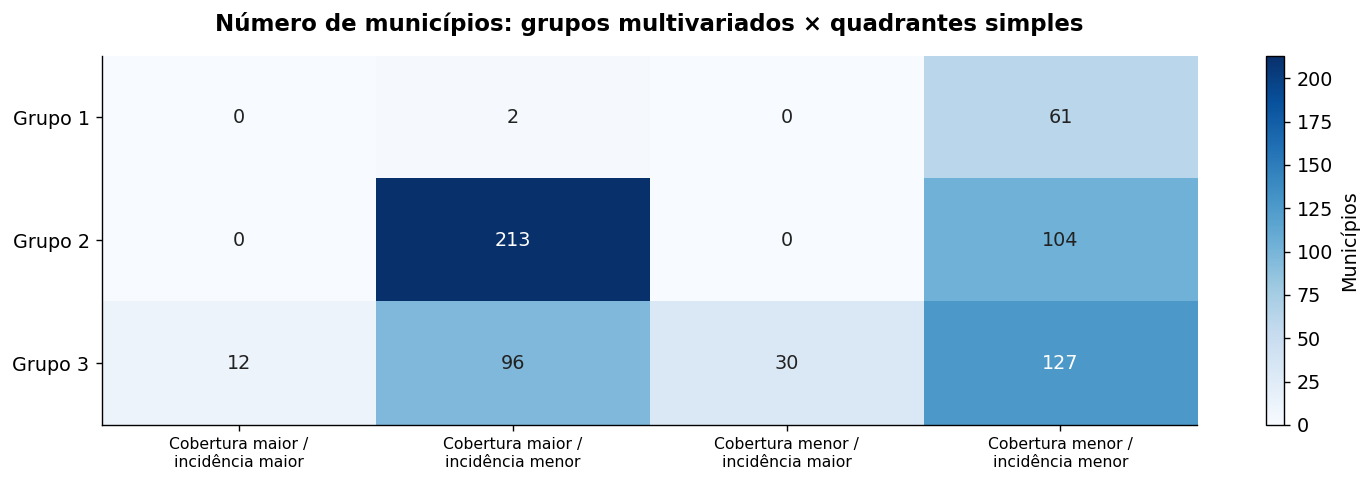

In [33]:
import textwrap
cruz=pd.crosstab(cl.grupo,cl.quadrante);display(cruz)
fig,ax=plt.subplots(figsize=(12,4));im=ax.imshow(cruz.to_numpy(),cmap='Blues',aspect='auto')
ax.set_yticks(range(K),[f'Grupo {g}' for g in cruz.index]);ax.set_xticks(range(len(cruz.columns)),[textwrap.fill(x,24) for x in cruz.columns],fontsize=9)
for i in range(K):
    for j in range(len(cruz.columns)):ax.text(j,i,str(cruz.iloc[i,j]),ha='center',va='center',color='white' if cruz.iloc[i,j]>cruz.to_numpy().max()/2 else '#222')
ax.set_title('Número de municípios: grupos multivariados × quadrantes simples');fig.colorbar(im,ax=ax,label='Municípios');plt.tight_layout();plt.show()
assert len(cl)==645 and cl.index.is_unique and cl.casos.sum()==18025
assert cl.grupo.between(1,K).all() and cl.concordancia_reamostragem.between(0,1).all()
assert perfis_cl.n.sum()==645 and perfis_cl.casos.sum()==18025
assert len(estab_cl)==40 and len(jacc_cl)==40*K
assert cruz.to_numpy().sum()==645
print('Auditoria clustering: municípios, casos, reamostragens, grupos e tabelas reconciliados.')

### 13.8 Conclusão: o clustering funcionou?

**Funcionou como resumo exploratório parcialmente robusto, não como descoberta de categorias definitivas.** Encontrou uma solução de três perfis interpretáveis, estável à retirada aleatória de municípios, com sobreposição e dependência das escolhas de dados.

O principal acréscimo ao gráfico simples é distinguir, entre municípios pouco atingidos, um perfil de cobertura registrada menor e em aumento de outro com cobertura registrada maior. A solução também identifica um conjunto mais denso com praticamente toda a carga de casos. Contudo, a incidência faz parte da definição, e os dados vacinais administrativos condicionam fortemente a interpretação.

**O que podemos apresentar:** três perfis de uma tipologia retrospectiva, seus tamanhos, distribuições, estabilidade e fragilidades. **O que não podemos afirmar:** que existem exatamente três tipos naturais de municípios, que um perfil causa doença, que municípios sem casos são seguros, ou que cobertura administrativa elevada garantiu proteção.

Para uma apresentação curta, o gráfico de quadrantes é a primeira escolha pela transparência. O clustering complementa a análise quando a trajetória vacinal e o contexto demográfico importam. Se fosse necessário tomar decisões práticas, os rótulos isolados seriam insuficientes: seria preciso verificar dados locais, limites dos grupos e atualização epidemiológica.

A distinção central do projeto permanece: **a predição espacial teve desempenho fraco; o clustering obteve uma descrição estável sob algumas perturbações.** São objetivos diferentes e um resultado não corrige o outro.

Reprodução: `python scripts/clustering.py` ou `RECALCULAR_CLUSTERING=True` no notebook. Dados derivados, rótulos por município, k=2 alternativo, perfis, estabilidade e sensibilidades estão em `results/clustering`. As fontes originais e os resultados da seção 12 são preservados.